In [94]:
import itertools
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2_contingency
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedGroupKFold

sys.path.insert(0, str(Path.cwd().parent))

from config import config
from domain.ipm import (
    CARACTERISTICAS_NUEVAS,
    INDICADORES_ELIMINADOS,
    IPM,
    ORIGINALES_NUEVAS,
)
from domain.variables_naming import ARCHIVOS, VARIABLES, variables_ipm_dane
from utils.cat_cat_dep import hub_pruebas_cat_cat
from utils.fancy_barplot import fancy_bars
from utils.join_plots import discrete_plot_joint
from utils.triple_plot import normality_report
from utils.vif_resume import vif_table

sklearn.set_config(transform_output="pandas")

# Consolidar Tabla Final

**Asistido por Claude Opus 5.5**

Dado que la parte de modelamiento del paper se realiza sobre un solo año se decidio utilizar solo la ECV correspondiente al 2025 ya que es la mas reciente que se tiene hasta el momento

## Objetivo:

Generar un modelo capaz de clacificar si un hogar es multidimensionalmente pobre, por lo tanto el sujeto de estudio es el hogar y no el individuo.

In [95]:
CSV_DIR = config.EXTRACTED / "ECV_2025_extracted" / "csv"

KEY_COLS = ["DIRECTORIO", "SECUENCIA_ENCUESTA", "SECUENCIA_P", "ORDEN"]
SHORT = {
    "DIRECTORIO": "D",
    "SECUENCIA_ENCUESTA": "SE",
    "SECUENCIA_P": "SP",
    "ORDEN": "ORDEN",
}

DF_SIZES = {}

# combinaciones que se usan a lo largo del notebook
D_SE = ["DIRECTORIO", "SECUENCIA_ENCUESTA"]
D_SP = ["DIRECTORIO", "SECUENCIA_P"]
D_SP_ORDEN = ["DIRECTORIO", "SECUENCIA_P", "ORDEN"]

# alias corto -> nombre del archivo, para no arrastrar tildes en el código
FILES = {
    "vivienda": "Datos de la vivienda.csv",
    "servicios": "Servicios del hogar.csv",
    "tenencia": (
        "Tenencia y financiacion de la vivienda que ocupa el hogar.csv"
    ),
    "condiciones": "Condiciones de vida del hogar y tenencia de bienes.csv",
    "adquisicion": "Adquisición de bienes y servicios.csv",
    "caracteristicas": "Características y composición del hogar.csv",
    "salud": "Salud.csv",
    "diseno": "Variables diseño muestral.csv",
    "educacion": "Educación.csv",
    "tic": "Tecnologías de información y comunicación.csv",
    "fuerza_trabajo": "Fuerza de trabajo.csv",
    "trabajo_infantil": "Trabajo infantil.csv",
    "menores_5": (
        "Atención integral de los niños y niñas menores de 5 años.csv"
    ),
    "item": "Adquisición de bienes y servicios por ítem.CSV",
    "programas": (
        "Condiciones de vida del hogar y tenencia de bienes (programas).csv"
    ),
    "escritura": (
        "Tenencia y financiacion de la vivienda que ocupa el hogar "
        "(personas escritura).csv"
    ),
    "pdet": "FEX_PDET_VIV_2025.csv",
}

# columnas auxiliares que se cargan junto con las llaves
EXTRA_COLS = {
    "servicios": ["CANT_PERSONAS_HOGAR"],
    "item": ["P3204"],
    "escritura": ["P8692S3A1"],
}

In [96]:
def read_data(alias, extra=()):
    """Lee las columnas llave presentes en el archivo, más `extra`."""
    path = CSV_DIR / FILES[alias]
    decimal = "." if alias == "item" else ","
    if alias == "vivienda":
        return pd.read_csv(
            path,
            sep=";",
            decimal=decimal,
            dtype={"P1_DEPARTAMENTO": str, "P1_MUNICIPIO": str},
        )
    return pd.read_csv(path, sep=";", decimal=decimal)

In [97]:
keys = {alias: read_data(alias, EXTRA_COLS.get(alias, ())) for alias in FILES}

In [98]:
keys["vivienda"]

,DIRECTORIO,SECUENCIA_ENCUESTA,SECUENCIA_P,ORDEN,P1_DEPARTAMENTO,P1_MUNICIPIO,REGION,FEX_C,CANT_HOG_COMPLETOS,CANT_HOGARES_VIVIENDA,...,P5661S9,P5661S5,P5661S6,P5661S7,P3157,P3157S1,P3157S2,P3157S3,P3157S4,P3158
0,8369550,1,1,1,13,1,1,472.131901,1,1,...,1,1,1,1,NaN,2,2,2,2,2
1,8369551,1,1,1,13,1,1,308.854319,1,1,...,1,1,2,1,NaN,2,2,2,2,2
2,8369552,1,1,1,13,1,1,428.516239,1,1,...,1,2,2,2,NaN,2,1,1,1,2
3,8369553,1,1,1,13,1,1,268.976656,1,1,...,1,2,3,3,NaN,1,1,1,1,1
4,8369554,1,1,1,13,1,1,353.949442,1,1,...,1,1,2,1,NaN,2,2,2,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
86843,8489518,1,1,1,99,524,9,23.804410,1,1,...,1,1,1,1,NaN,2,2,2,2,2
86844,8489519,1,1,1,99,524,9,19.043528,1,1,...,1,1,1,1,NaN,2,2,2,2,2
86845,8489520,1,1,1,99,524,9,19.043528,1,1,...,1,1,1,1,NaN,2,2,2,2,2
86846,8489521,1,1,1,99,524,9,19.043528,1,1,...,1,1,1,1,NaN,2,2,2,2,2


Una vez cargadas todas las tablas de manera individual se procede a consolidar las variables de interes, expuestas en la siguiente tabla, con su uso ya sea corte o modelamiento, y su nombre segun el diseño de la encuesta. Ademas antes de iniciar con el EDA y analisis previos al modelamiento se opta por realizar el Dual Cutoff Method (para crear la variable binaria objetivo) utilizando los cortes que el DANE reporta, adicionalmente se evita que variables que actuen en el corte se solapen con las predictoras. 

## Consolidar DF

La tabla final queda a **nivel persona**: una fila por persona con todas las
variables de la ECV 2025. Los cruces usan las llaves verificadas en
`full_analisis.ipynb`:

| Nivel | Llave en su archivo | Con qué se cruza en la tabla final |
| --- | --- | --- |
| vivienda | `DIRECTORIO` | `DIRECTORIO` |
| hogar | `DIRECTORIO` + `SECUENCIA_ENCUESTA` | `DIRECTORIO` + `SECUENCIA_P` |
| persona | `DIRECTORIO` + `SECUENCIA_P` + `ORDEN` | las mismas tres |

Tres detalles que salen de ese análisis:

- En los archivos de persona `SECUENCIA_ENCUESTA` repite lo que ya dice
  `ORDEN`, así que se descarta y la llave de persona queda `D + SP + ORDEN`.
- El hogar se llama `SECUENCIA_ENCUESTA` en los archivos de hogar y
  `SECUENCIA_P` en los de persona; por eso se renombra antes de cruzar.
- `FEX_C` es la única columna no llave que aparece en los 13 archivos. Se
  conserva solo la de `diseno`, porque `condiciones` y `diseno` difieren del
  resto en 4.553 hogares por redondeo.

Las variables de hogar y de vivienda **se repiten en cada integrante del
hogar**, que es lo que necesita el procesamiento posterior. `item`,
`programas` y `escritura` quedan fuera: traen varias filas por hogar y no
caben en una tabla de una fila por persona sin agregarlas antes.

In [99]:
# archivos que aportan una fila por persona y una fila por hogar
PERSON_FILES = [
    "salud",
    "diseno",
    "educacion",
    "tic",
    "fuerza_trabajo",
    "trabajo_infantil",
    "menores_5",
]
HOUSEHOLD_FILES = ["servicios", "tenencia", "condiciones", "adquisicion"]

In [100]:
# base: una fila por persona. SECUENCIA_ENCUESTA se descarta porque repite
# a ORDEN; FEX_C se conserva solo desde 'diseno'.
df = keys["caracteristicas"].drop(columns=["SECUENCIA_ENCUESTA", "FEX_C"])

for alias in PERSON_FILES:
    drop_cols = ["SECUENCIA_ENCUESTA"]
    if alias != "diseno":
        drop_cols.append("FEX_C")
    right = keys[alias].drop(columns=drop_cols, errors="ignore")
    df = df.merge(right, on=D_SP_ORDEN, how="left", validate="1:1")

print(df.shape)

(235350, 567)


In [101]:
# el hogar es SECUENCIA_ENCUESTA en estos archivos y SECUENCIA_P en la
# tabla de personas: se renombra para cruzar por D + SP
for alias in HOUSEHOLD_FILES:
    right = (
        keys[alias]
        .drop(columns=["SECUENCIA_P", "ORDEN", "FEX_C"])
        .rename(columns={"SECUENCIA_ENCUESTA": "SECUENCIA_P"})
    )
    df = df.merge(right, on=D_SP, how="left", validate="m:1")

print(df.shape)

(235350, 861)


In [102]:
# vivienda: sus SE, SP y ORDEN valen siempre 1, no aportan nada
right = keys["vivienda"].drop(
    columns=["SECUENCIA_ENCUESTA", "SECUENCIA_P", "ORDEN", "FEX_C"]
)
df = df.merge(right, on="DIRECTORIO", how="left", validate="m:1")

print(df.shape)

(235350, 902)


In [103]:
DF_SIZES["Tamaño Inicial"] = df.shape[0]

In [104]:
print(f"personas: {len(df)}")  # esperado 235350
print(
    f"iguales a 'caracteristicas': {len(df) == len(keys['caracteristicas'])}"
)
print(f"personas repetidas: {df.duplicated(subset=D_SP_ORDEN).sum()}")  # 0
print(
    f"columnas con sufijo: {[c for c in df.columns if c[-2:] in ('_x', '_y')]}"
)
print(f"hogares: {df[D_SP].drop_duplicates().shape[0]}")  # esperado 87060
print(f"viviendas: {df['DIRECTORIO'].nunique()}")  # esperado 86848

personas: 235350
iguales a 'caracteristicas': True
personas repetidas: 0
columnas con sufijo: []
hogares: 87060
viviendas: 86848


In [105]:
# los indicadores de hogar deben ser idénticos para todas las personas
# del hogar: un solo valor distinto por hogar
hogar_vars = ["CANT_PERSONAS_HOGAR", "PERCAPITA", "I_HOGAR", "P5000"]
print(df.groupby(D_SP)[hogar_vars].nunique().max())  # esperado 1 en todas

CANT_PERSONAS_HOGAR    1
PERCAPITA              1
I_HOGAR                1
P5000                  1
dtype: int64


1 significa: en el hogar más desviado de toda la encuesta, esa variable tiene un solo valor distinto. Es decir, no existe ni un hogar donde dos miembros tengan valores diferentes de un indicador de hogar

In [106]:
# la vivienda de dos hogares del contraejemplo de full_analisis.ipynb:
# CANT_PERSONAS_HOGAR se repite dentro del hogar, la edad cambia por persona
cols = [*D_SP_ORDEN, "CANT_PERSONAS_HOGAR", "P6040"]  # P6040 = edad
display(df[df["DIRECTORIO"] == 8370223][cols])

,DIRECTORIO,SECUENCIA_P,ORDEN,CANT_PERSONAS_HOGAR,P6040
1522,8370223,1,1,3,72
1523,8370223,1,2,3,45
1524,8370223,1,3,3,27
1525,8370223,2,1,2,48
1526,8370223,2,2,2,20


Totales de control: **235.350 personas**, 87.060 hogares y 86.848 viviendas,
los mismos del análisis de llaves.

Un `NaN` que venga de un módulo de persona (`educacion`, `tic`,
`fuerza_trabajo`, `trabajo_infantil`, `menores_5`) significa que **a esa
persona no le aplicaba el módulo** por edad, no que la respuesta falte:
`educacion` y `tic` cubren 221.043 personas, `fuerza_trabajo` 195.074,
`trabajo_infantil` 25.969 y `menores_5` 14.307.

El `validate=` de cada cruce es la red de seguridad: `1:1` en los módulos de
persona y `m:1` en hogar y vivienda, así que una llave equivocada levanta un
error en vez de multiplicar filas en silencio.

## Analisis general de tipos de datos

In [107]:
df.dtypes.value_counts()

float64    699
int64      200
str          3
Name: count, dtype: int64

In [108]:
cols_str = df.select_dtypes(include=["object", "string", "str"]).columns
print(cols_str)

Index(['BLOQUE', 'P1_DEPARTAMENTO', 'P1_MUNICIPIO'], dtype='str')


In [109]:
df["BLOQUE"]

0         A00013
1         A00013
2         A00013
3         A00013
4         A00013
           ...  
235345    R34C02
235346    R34C02
235347    R34C02
235348    R34C02
235349    R34C02
Name: BLOQUE, Length: 235350, dtype: str

In [110]:
for k, frame in keys.items():
    if "BLOQUE" in frame.columns:
        print(k)

diseno


`BLOQUE` es la única columna de texto de la tabla final y la única que no es
una respuesta de la encuesta: 

- **No es una predictora**, es una variable de diseño. Al armar la matriz del
  modelo hay que excluirla.
- `BLOQUE` es la partición geográfica en la que el DANE calibra los factores de expansión.
- Sirve para estimaciones por dominio (departamento, cabecera/resto) y, junto
  con `FEX_C`, `ESTRATO2020` y `SEGMENTO`, para calcular errores estándar
  respetando el diseño complejo de la encuesta.

### Usos posibles de `BLOQUE` (aportado por Claude Opus 5.5)

- Para estratificar el split. Separar train y test por BLOQUE y por el target mantiene la representatividad territorial, con SEGMENTO como grupo en el GroupKFold.
- Para evaluar el modelo. Mide el desempeño por bloque y así se ve si falla sistemáticamente en zonas rurales o en ciudades concretas.

In [111]:
df["BLOQUE"].nunique()

94

# Renombrar Columnas
**Asistido por claude Opus 5.5**

In [112]:
import re
import unicodedata

CODE_RE = re.compile(r"^P\d+[A-Za-z0-9]*$")
# F24 trae los sufijos en minúscula (P8587s1) y los CSV en mayúscula
V_UP = {k.upper(): v for k, v in VARIABLES.items()}


def _slug(texto):
    """Pasa la pregunta completa a snake_case sin tildes ni numeración."""
    t = re.sub(r"^\d+[A-Za-z]?\.\s*", "", texto)  # quita "4. ", "12A. "
    t = unicodedata.normalize("NFKD", t)
    t = t.encode("ascii", "ignore").decode()  # quita tildes
    return re.sub(r"[^0-9A-Za-z]+", "_", t).strip("_").lower()


def build_rename(columns):
    """código -> 'CÓDIGO_pregunta'; deja intacto lo que no es un P-código.

    El código se busca con `col.split("_")[0]`, así que la celda se puede
    volver a correr sobre un df que ya trae los nombres largos.
    """
    mapa = {}
    for col in columns:
        codigo = col.split("_")[0]
        info = V_UP.get(codigo.upper())
        if info and CODE_RE.match(codigo):
            pregunta = _slug(info["pregunta"])
            if pregunta:
                mapa[col] = f"{codigo}_{pregunta}"
    return mapa

In [113]:
rename_map = build_rename(df.columns)
df_renamed = df.rename(columns=rename_map)

print(f"renombradas: {len(rename_map)}")  # esperado 629
print(f"intactas: {df.shape[1] - len(rename_map)}")  # esperado 273
print(f"forma: {df.shape}")  # esperado (235350, 902)
print(f"nombres repetidos: {df.columns.duplicated().sum()}")  # esperado 0
print(f"llaves intactas: {all(c in df for c in [*D_SP_ORDEN, 'FEX_C'])}")
display(pd.Series(rename_map).head(8).to_frame("nombre nuevo"))

renombradas: 629
intactas: 273
forma: (235350, 902)
nombres repetidos: 0
llaves intactas: True


,nombre nuevo
P6016,P6016_numero_de_orden_de_la_persona_que_propor...
P1894,P1894_tipo_de_documento_de_identidad
P6020,P6020_sexo_al_nacer
P6034,P6034_cual_es_la_fecha_de_nacimiento_de
P6040,P6040_cuantos_anos_cumplidos_tiene
P6051,P6051_cual_es_el_parentesco_de_con_el_jefe_o_l...
P5502,P5502_actualmente_estado_civil
P6071,P6071_el_la_conyuge_de_vive_en_este_hogar


### Renombrar las columnas con `VARIABLES`

Cada columna que es un código ECV pasa a `CÓDIGO_pregunta`, con el texto
completo de la pregunta normalizado: sin tildes, en `snake_case` y sin la
numeración del cuestionario. Los nombres quedan largos (mediana 63
caracteres, máximo 111), pero no hay ambigüedad: en las familias de preguntas
se conserva tanto el encabezado común como la etiqueta que distingue
(`P1077S1` → `P1077S1_bienes_o_servicios_que_posee_el_hogar_lavadora_de_ropa`).

**El código se conserva al frente a propósito**: el IPM que falta especificar
en `variables_naming.py` indexa por código, y `col.split("_")[0]` lo recupera
sin necesidad de un diccionario inverso. Por eso mismo la celda se puede
volver a correr sobre un `df` ya renombrado.

**Qué queda intacto** (273 columnas):

- Las llaves (`DIRECTORIO`, `SECUENCIA_P`, `ORDEN`) y el bloque de diseño
  (`FEX_C`, `BLOQUE`, `SEGMENTO`, `ESTRATO2020`, `MPIO`, `F2`, `F_ETAPA1`,
  `FRES`), más `PERCAPITA`, `I_HOGAR`, `I_UGASTO`, `I_OU`,
  `CANT_PERSONAS_HOGAR`, `CLASE`, `REGION`, `P1_DEPARTAMENTO` y
  `P1_MUNICIPIO`: ya son nombres legibles y renombrarlos rompería `D_SP` y los
  chequeos de arriba.
- **251 columnas sin etiqueta en `VARIABLES`**, que siguen con su código
  pelado: `salud` 81, `adquisicion` 41, `caracteristicas` 33, `tic` 22,
  `menores_5` 22, `condiciones` 16, `servicios` 12, `educacion` 10,
  `fuerza_trabajo` 9, `vivienda` 4 y `trabajo_infantil` 1.

`adquisicion` no tiene ninguna etiqueta porque *"Adquisición de bienes y
servicios"* no está en `ARCHIVOS`; si esas 41 variables se van a usar, hay que
agregarlas al diccionario.

In [114]:
df

,DIRECTORIO,SECUENCIA_P,ORDEN,P6016,P1894,P6020,P6034,P6040,P6051,P5502,...,P5661S9,P5661S5,P5661S6,P5661S7,P3157,P3157S1,P3157S2,P3157S3,P3157S4,P3158
0,8369550,1,1,1,3,2,1,45,1,5.0,...,1,1,1,1,NaN,2,2,2,2,2
1,8369550,1,2,2,3,1,1,25,7,4.0,...,1,1,1,1,NaN,2,2,2,2,2
2,8369550,1,3,3,2,2,1,16,9,5.0,...,1,1,1,1,NaN,2,2,2,2,2
3,8369550,1,4,4,2,1,1,10,9,5.0,...,1,1,1,1,NaN,2,2,2,2,2
4,8369551,1,1,1,3,2,1,62,1,3.0,...,1,1,2,1,NaN,2,2,2,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
235345,8489520,1,2,2,3,2,1,31,2,2.0,...,1,1,1,1,NaN,2,2,2,2,2
235346,8489520,1,3,3,1,2,1,8,3,NaN,...,1,1,1,1,NaN,2,2,2,2,2
235347,8489521,1,1,1,3,1,1,31,1,2.0,...,1,1,1,1,NaN,2,2,2,2,2
235348,8489521,1,2,2,3,2,1,32,2,2.0,...,1,1,1,1,NaN,2,2,2,2,2


# Crear variable objetivo

En esta estapa mas alla de usar el enfoque que uso el paper para el corte se utiliza la forma de realizar el corte replicando el procedimiento reportado por el DANE para la propia ECV del 2025 y se evaluara el corte con el mismo metodo del paper. Cabe resaltar que el DANE usa el mismo enfoque que el paper, pues usa la metodologia de Alkire Foster y el enfoque de Sen

Nota: las variables que se usen para realizar los cortes solo se utilizaran en esta etapa, ademas no se hace sobre el set cortado ya que al ser una etapa de consolidacion cada corte se basa en los datos de un solo hogar, por lo tanto finalmente solo habra una fila por hogar, es decir no hay fuga porque los cortes solo se basan en datos de si mismo.

## Replicar al DANE

Los indicadores, pesos y criterios de privacion que utiliza el DANE en las 4 dimensiones que define (a diferencia de las 5 que el paper utiliza) son:

| Dimensión (peso 0,20) | Indicador | w | z: el hogar está privado si… |
|---|---|---|---|
| Condiciones educativas | Bajo logro educativo | 0,10 | El promedio de años de educación de las personas mayores de 15 años es menor a 9. Los hogares sin mayores de 15 años se consideran privados. |
| Condiciones educativas | Analfabetismo | 0,10 | Al menos una persona mayor de 15 años no sabe leer ni escribir. Los hogares sin mayores de 15 años se consideran privados. |
| Niñez y juventud | Rezago escolar | 0,05 | Al menos un miembro de 7 a 17 años tiene menos años de educación que (edad − 6), por ejemplo, 17 años con menos de 11 años de educación. Los hogares sin miembros de 7 a 17 años no están privados. |
| Niñez y juventud | Inasistencia escolar | 0,05 | Al menos un niño de 6 a 16 años no estudia actualmente. Los hogares sin niños de 6 a 16 años no están privados. |
| Niñez y juventud | Barreras de acceso a servicios de cuidado de la primera infancia | 0,05 | Al menos un niño de 0 a 5 años cumple alguna de estas condiciones: no está asegurado en salud; permanece con su padre o madre en el trabajo, solo en casa o al cuidado de un pariente menor de 18 años; asiste a un jardín o institución educativa pero no recibe alimentación gratis o por un pago simbólico; o, si tiene 5 años, no asiste a una institución educativa. |
| Niñez y juventud | Trabajo infantil | 0,05 | Al menos un miembro de 12 a 17 años está ocupado. |
| Salud | Sin aseguramiento en salud | 0,10 | Al menos un miembro mayor de 5 años no está afiliado a salud. La respuesta "No sabe / No informa" cuenta como no afiliado. |
| Salud | Barreras de acceso a servicios de salud dada una necesidad | 0,10 | Al menos una persona que tuvo un problema de salud en los últimos 30 días no acudió a un médico general, especialista, odontólogo, terapista o institución de salud. Los hogares sin problemas de salud no están privados. |
| Trabajo | Desempleo de larga duración | 0,10 | Al menos una persona de la PEA lleva más de 12 meses buscando trabajo. Los hogares sin PEA o compuestos solo por pensionados se consideran privados. |
| Trabajo | Trabajo informal | 0,10 | No todos los ocupados de la PEA ajustada (sin ocupados menores de 18 años ni desempleados de larga duración) cotizan a pensión o están pensionados. Los hogares sin PEA ajustada están privados; los compuestos solo por pensionados no. |
| Vivienda y servicios públicos | Sin acceso a fuente de agua mejorada | 0,04 | En zona urbana: no tiene acueducto. En zona rural: obtiene el agua para preparar alimentos de pozo sin bomba, agua lluvia, río o manantial, carrotanque, aguatero, o agua embotellada o en bolsa. |
| Vivienda y servicios públicos | Inadecuada eliminación de excretas | 0,04 | En zona urbana: no tiene alcantarillado. En zona rural: tiene inodoro sin conexión, bajamar o no tiene servicio sanitario. |
| Vivienda y servicios públicos | Material inadecuado de pisos | 0,04 | Tiene pisos en tierra. |
| Vivienda y servicios públicos | Material inadecuado de paredes exteriores | 0,04 | En zona urbana: las paredes son de madera burda, tabla, tablón, guadua, otro vegetal, zinc, tela, cartón o desechos, o no tiene paredes. En zona rural: guadua, otro vegetal, zinc, tela, cartón o desechos, o no tiene paredes. |
| Vivienda y servicios públicos | Hacinamiento crítico | 0,04 | En zona urbana: 3 o más personas por cuarto. En zona rural: más de 3 personas por cuarto. |

**Corte de pobreza (k):** un hogar es pobre por IPM si la suma ponderada de sus privaciones es mayor o igual a 5/15 (33,3%).

Note ademas que cada una de las dimensiones reparte su peso de manera igual entre los diferentes indicadores.

### Que variables de las 902 tomar?

A continuacion se listan las variables que se identificaron utiles (con ayuda de Claude Opus 5.5) para replicar este metodo:

| Bloque | Variable (código ECV 2025) | Archivo | Descripción | Indicador(es) que alimenta |
|---|---|---|---|---|
| Identificadores | DIRECTORIO | Todos | Identificador de la vivienda | Llave para unir todos los archivos |
| Identificadores | SECUENCIA_ENCUESTA | Todos | Número de hogar (en archivos de hogar) o de persona (en archivos de personas) | Llave para unir archivos |
| Identificadores | SECUENCIA_P | Todos | Número de hogar dentro de la vivienda (en archivos de personas) | Llave para unir archivos |
| Identificadores | ORDEN | Todos | Número de persona dentro del hogar | Llave para unir archivos |
| Identificadores | FEX_C | Todos | Factor de expansión | Expansión de resultados |
| Personas | P6040 | Características y composición del hogar | Edad en años cumplidos | Todos los filtros por edad |
| Personas | P6020 | Características y composición del hogar | Sexo al nacer | Desagregaciones |
| Personas | P6051 | Características y composición del hogar | Parentesco con el jefe del hogar | Identificación de miembros del hogar |
| Educación | P6160 | Educación | ¿Sabe leer y escribir? | Analfabetismo |
| Educación | P8586 | Educación | ¿Actualmente estudia? | Inasistencia escolar, logro educativo, rezago escolar, primera infancia (niños de 5 años) |
| Educación | P8587 | Educación | Nivel educativo más alto alcanzado | Logro educativo, rezago escolar |
| Educación | P8587S1 | Educación | Grado o año aprobado en ese nivel | Logro educativo, rezago escolar |
| Educación | P1088 | Educación | Nivel en el que está matriculado | Logro educativo, rezago escolar |
| Educación | P1088S1 | Educación | Grado o año que cursa | Logro educativo, rezago escolar |
| Educación | P6180 | Educación | ¿Recibe alimentos en el plantel gratis o por pago simbólico? | Primera infancia (niños de 5 años) |
| Primera infancia | P51 | Atención integral de menores de 5 años | Dónde o con quién permanece la mayor parte del tiempo entre semana | Barreras de acceso a cuidado de la primera infancia |
| Primera infancia | P55 | Atención integral de menores de 5 años | ¿Recibe desayuno o almuerzo en el lugar donde permanece? | Barreras de acceso a cuidado de la primera infancia |
| Primera infancia | P774 | Atención integral de menores de 5 años | ¿Paga por esta alimentación? | Barreras de acceso a cuidado de la primera infancia |
| Salud | P6090 | Salud | Afiliación a seguridad social en salud | Sin aseguramiento en salud, primera infancia |
| Salud | P5665 | Salud | ¿Tuvo un problema de salud en los últimos 30 días sin hospitalización? | Barreras de acceso a salud dada una necesidad |
| Salud | P8563 | Salud | ¿Qué hizo principalmente para tratar ese problema de salud? | Barreras de acceso a salud dada una necesidad |
| Fuerza de trabajo | P6240 | Fuerza de trabajo | Actividad en la que ocupó la mayor parte del tiempo la semana pasada | Trabajo infantil, desempleo de larga duración, trabajo informal |
| Fuerza de trabajo | P6250 | Fuerza de trabajo | ¿Realizó alguna actividad paga por una hora o más? | Trabajo infantil, desempleo de larga duración, trabajo informal |
| Fuerza de trabajo | P6260 | Fuerza de trabajo | ¿Tenía trabajo o negocio aunque no trabajó? | Trabajo infantil, desempleo de larga duración, trabajo informal |
| Fuerza de trabajo | P6270 | Fuerza de trabajo | ¿Trabajó en un negocio sin que le pagaran? | Trabajo infantil, desempleo de larga duración, trabajo informal |
| Fuerza de trabajo | P6280 | Fuerza de trabajo | ¿Hizo diligencias para conseguir trabajo en las últimas 4 semanas? | Desempleo de larga duración (definición de desocupado) |
| Fuerza de trabajo | P6351 | Fuerza de trabajo | ¿Estaba disponible la semana pasada para empezar a trabajar? | Desempleo de larga duración (definición de desocupado) |
| Fuerza de trabajo | P7250 | Fuerza de trabajo | Semanas buscando trabajo (privado si son más de 52) | Desempleo de larga duración |
| Fuerza de trabajo | P6920 | Fuerza de trabajo | ¿Cotiza actualmente a un fondo de pensiones? | Trabajo informal |
| Fuerza de trabajo | P8642 | Fuerza de trabajo | ¿Recibió el mes pasado ingreso por pensión? (condición de pensionado) | Trabajo informal, desempleo de larga duración |
| Vivienda y servicios | CLASE | Datos de la vivienda | Cabecera (urbano) o resto (rural) | Agua, excretas, paredes, hacinamiento |
| Vivienda y servicios | P8520S5 | Datos de la vivienda | ¿Tiene acueducto? | Sin acceso a fuente de agua mejorada (urbano) |
| Vivienda y servicios | P8520S3 | Datos de la vivienda | ¿Tiene alcantarillado? | Inadecuada eliminación de excretas (urbano) |
| Vivienda y servicios | P4015 | Datos de la vivienda | Material predominante de los pisos | Material inadecuado de pisos |
| Vivienda y servicios | P4005 | Datos de la vivienda | Material predominante de las paredes exteriores | Material inadecuado de paredes exteriores |
| Vivienda y servicios | P8530 | Servicios del hogar | Fuente principal del agua para preparar alimentos | Sin acceso a fuente de agua mejorada (rural) |
| Vivienda y servicios | P8526 | Servicios del hogar | Tipo de servicio sanitario | Inadecuada eliminación de excretas (rural) |
| Vivienda y servicios | P5010 | Servicios del hogar | Número de cuartos en que duermen las personas del hogar | Hacinamiento crítico |
| Vivienda y servicios | CANT_PERSONAS_HOGAR | Servicios del hogar | Número de personas que componen el hogar | Hacinamiento crítico |

**Notas:**
- Códigos verificados en el diccionario de la ECV 2025 (microdatos.dane.gov.co, catálogo 905).

- Si P6051 = 1 -> persona es jefe del hogar

- P1088 indica el nivel educativo en el que la persona está matriculada actualmente: preescolar, básica primaria, básica secundaria, media, técnico, tecnológico, universitario, posgrado, etc. P1088S1 indica el grado o año que cursa dentro de ese nivel. Por ejemplo, P1088 = básica secundaria y P1088S1 = 8 significa que la persona está en octavo grado.

**Nota:** Antes de realizar el metodo se filtra el df a aquellos valores que son CLASE=

### Filtrar solo ciudades

In [115]:
df = df.copy()
df.columns = df.columns.str.upper()

dpto = df["P1_DEPARTAMENTO"].str.zfill(2)
mpio = df["P1_MUNICIPIO"].str.zfill(3)
df["DIVIPOLA"] = dpto + mpio

df["CIUDAD"] = pd.to_numeric(df["CLASE"], errors="coerce").eq(1)

df_ciudades = df[df["CIUDAD"]]

In [116]:
df_ciudades

,DIRECTORIO,SECUENCIA_P,ORDEN,P6016,P1894,P6020,P6034,P6040,P6051,P5502,...,P5661S6,P5661S7,P3157,P3157S1,P3157S2,P3157S3,P3157S4,P3158,DIVIPOLA,CIUDAD
0,8369550,1,1,1,3,2,1,45,1,5.0,...,1,1,NaN,2,2,2,2,2,13001,True
1,8369550,1,2,2,3,1,1,25,7,4.0,...,1,1,NaN,2,2,2,2,2,13001,True
2,8369550,1,3,3,2,2,1,16,9,5.0,...,1,1,NaN,2,2,2,2,2,13001,True
3,8369550,1,4,4,2,1,1,10,9,5.0,...,1,1,NaN,2,2,2,2,2,13001,True
4,8369551,1,1,1,3,2,1,62,1,3.0,...,2,1,NaN,2,2,2,2,2,13001,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
235286,8489488,1,1,1,3,2,1,40,1,4.0,...,2,2,NaN,2,2,1,2,1,99624,True
235287,8489488,1,2,2,2,2,1,15,3,5.0,...,2,2,NaN,2,2,1,2,1,99624,True
235288,8489488,1,3,3,2,2,1,11,3,5.0,...,2,2,NaN,2,2,1,2,1,99624,True
235289,8489488,1,4,4,2,2,1,9,3,NaN,...,2,2,NaN,2,2,1,2,1,99624,True


In [117]:
DF_SIZES["Filtrar Ciudades"] = df_ciudades.shape[0]

In [118]:
cols = list(variables_ipm_dane.keys())
cols.remove("SECUENCIA_ENCUESTA")

df_ciudades[cols]

,DIRECTORIO,SECUENCIA_P,ORDEN,FEX_C,P1_DEPARTAMENTO,P1_MUNICIPIO,CLASE,P6040,P6020,P6051,...,P6920,P8642,P8520S5,P8520S3,P4015,P4005,P8530,P8526,P5010,CANT_PERSONAS_HOGAR
0,8369550,1,1,472.131901,13,1,1,45,2,1,...,2.0,2.0,1,1,4,1,1,1,3,4
1,8369550,1,2,472.131901,13,1,1,25,1,7,...,1.0,2.0,1,1,4,1,1,1,3,4
2,8369550,1,3,472.131901,13,1,1,16,2,9,...,2.0,2.0,1,1,4,1,1,1,3,4
3,8369550,1,4,472.131901,13,1,1,10,1,9,...,NaN,NaN,1,1,4,1,1,1,3,4
4,8369551,1,1,308.854319,13,1,1,62,2,1,...,2.0,2.0,1,1,4,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
235286,8489488,1,1,6.498987,99,624,1,40,2,1,...,2.0,2.0,1,2,7,1,2,2,2,5
235287,8489488,1,2,6.498987,99,624,1,15,2,3,...,2.0,2.0,1,2,7,1,2,2,2,5
235288,8489488,1,3,6.498987,99,624,1,11,2,3,...,NaN,NaN,1,2,7,1,2,2,2,5
235289,8489488,1,4,6.498987,99,624,1,9,2,3,...,NaN,NaN,1,2,7,1,2,2,2,5


Ya que la dimensionalidad del conjunto de datos es tan alta se aplicara una metodologia alternativa, por cada una de las dimensiones se extraeran 1 o 2 inducadores que en lugar de ser usados en el procedimiento de corte se usaran como caracterisitcas del modelo (refactorizar las entradas para el objeto de corte).

## Como lidear con la dimensionalidad (mas de 900 variables)
Bajo este contexto se plantea eliminar las siguientes variables:

- Analfabetismo
- Trabajo Infantil
- Tiene eps Si/No
- Trabajo Informal
- Sin acceso al agua
- Mala eliminacionde excretas.

Cabe destacar que esto da como un resultado una variable objetivo menos robusta, esto ya que se deriva de menos informacion de los hogares y en aquellas dimensiones que quedan con solo un indicador hogares que solo esten privada en esa dimension y otra ya se consideran multidimensionalmente pobres. Es una falla metodologica que vale la pena destacar.

### Despues de eliminar los indicadores queda asi.

| Dimensión | Peso dimensión | Indicador | Rol | w en el corte | Variables ECV que lo construyen | Nota |
|---|---|---|---|---|---|---|
| Educación | 0,20 | Logro educativo | Corte | 0,2000 | P6040, P8586, P8587, P8587S1, P6211, P1088, P1088S1, P6216 | Único indicador de la dimensión |
| Educación | — | Analfabetismo | Característica | — | P6160 | Revisar R0 frente a logro educativo |
| Niñez y juventud | 0,20 | Rezago escolar | Corte | 0,0667 | P6040, P8586, P8587, P8587S1, P6211, P1088, P1088S1, P6216 | |
| Niñez y juventud | 0,20 | Inasistencia escolar | Corte | 0,0667 | P6040, P8586 | |
| Niñez y juventud | 0,20 | Barreras de acceso a cuidado de primera infancia | Corte | 0,0667 | P6040, P6090, P51, P55, P774, P8586, P6180 | Usa P6090 para menores de 6 años |
| Niñez y juventud | — | Trabajo infantil | Característica | — | P6040, P6240, P6250, P6260, P6270 | P6240 a P6270 también definen la PEA del desempleo de larga duración |
| Salud | 0,20 | Barreras de acceso a salud dada una necesidad | Corte | 0,2000 | P5665, P8563 | Único indicador de la dimensión |
| Salud | — | Sin aseguramiento en salud | Característica | — | P6040, P6090 | Solo personas de 6 años o más; P6090 de menores de 6 años está en el corte |
| Trabajo | 0,20 | Desempleo de larga duración | Corte | 0,2000 | P6040, P6240, P6250, P6260, P6270, P6351, P7250, P6920, P8642 | Único indicador; hogares sin PEA o solo de pensionados quedan privados |
| Trabajo | — | Trabajo informal | Característica | — | P6040, P6240, P6250, P6260, P6270, P6351, P7250, P6920, P8642 | Comparte la PEA y la condición de pensionado con desempleo de larga duración |
| Vivienda y servicios | 0,20 | Material inadecuado de pisos | Corte | 0,0667 | P4015 | |
| Vivienda y servicios | 0,20 | Material inadecuado de paredes exteriores | Corte | 0,0667 | CLASE, P4005 | |
| Vivienda y servicios | 0,20 | Hacinamiento crítico | Corte | 0,0667 | CLASE, CANT_PERSONAS_HOGAR, P5010 | |
| Vivienda y servicios | — | Sin acceso a fuente de agua mejorada | Característica | — | CLASE, P8520S5, P8530 | Sin variables compartidas con el corte |
| Vivienda y servicios | — | Inadecuada eliminación de excretas | Característica | — | CLASE, P8520S3, P8526 | Sin variables compartidas con el corte |

**Corte de pobreza (k):** 5/15 (33,3%) sobre los 9 indicadores que quedan en el corte.

In [119]:
variables_liberadas = [
    "P6160",  # ¿Sabe leer y escribir? (analfabetismo)
    "P8520S5",  # ¿Tiene acueducto? (agua)
    "P8530",  # Fuente del agua para preparar alimentos (agua)
    "P8520S3",  # ¿Tiene alcantarillado? (excretas)
    "P8526",  # Tipo de servicio sanitario (excretas)
]

## Desarrollar doble corte usando la metodologia Alkire-Foster

Se aplica la adaptacion anteriormente descrita y se compara la robustes de esta frente a la robustes de la metodologia del dane, asimismo se procede a realizar la separacion en train, validation y test (esto antes de evaluar la robustes con el fin de evitar el data leakage). El metodo de doble corte se implemento como una clase compatible con el metodo Pipeline de sklearn para ser usado de manera mas robusta y confiable, cabe resaltar que el codigo se realizo con la asistencia de Claude opus 5.5.




In [120]:
df

,DIRECTORIO,SECUENCIA_P,ORDEN,P6016,P1894,P6020,P6034,P6040,P6051,P5502,...,P5661S6,P5661S7,P3157,P3157S1,P3157S2,P3157S3,P3157S4,P3158,DIVIPOLA,CIUDAD
0,8369550,1,1,1,3,2,1,45,1,5.0,...,1,1,NaN,2,2,2,2,2,13001,True
1,8369550,1,2,2,3,1,1,25,7,4.0,...,1,1,NaN,2,2,2,2,2,13001,True
2,8369550,1,3,3,2,2,1,16,9,5.0,...,1,1,NaN,2,2,2,2,2,13001,True
3,8369550,1,4,4,2,1,1,10,9,5.0,...,1,1,NaN,2,2,2,2,2,13001,True
4,8369551,1,1,1,3,2,1,62,1,3.0,...,2,1,NaN,2,2,2,2,2,13001,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
235345,8489520,1,2,2,3,2,1,31,2,2.0,...,1,1,NaN,2,2,2,2,2,99524,False
235346,8489520,1,3,3,1,2,1,8,3,NaN,...,1,1,NaN,2,2,2,2,2,99524,False
235347,8489521,1,1,1,3,1,1,31,1,2.0,...,1,1,NaN,2,2,2,2,2,99524,False
235348,8489521,1,2,2,3,2,1,32,2,2.0,...,1,1,NaN,2,2,2,2,2,99524,False


In [121]:
ipm = IPM(caracteristicas=INDICADORES_ELIMINADOS)
ipm.fit(df_ciudades)

,caracteristicas,"['analfabetismo', 'trabajo_infantil', ...]"
,indicadores,None
,w,None
,k,None
,codigos,None
,caracteristicas_nan,False
,claves_hogar,"('DIRECTORIO', ...)"
,col_peso,'FEX_C'
,col_clase,'CLASE'
Name,Type,Value
caracteristicas_,list,"['an...mo', 'tr...il', 'si...to', 'tr...al', ...]"


In [122]:
ipm.w_

{'logro_educativo': np.float64(0.2),
 'rezago_escolar': np.float64(0.06666666666666667),
 'inasistencia_escolar': np.float64(0.06666666666666667),
 'primera_infancia': np.float64(0.06666666666666667),
 'barreras_salud': np.float64(0.2),
 'desempleo_larga': np.float64(0.2),
 'pisos': np.float64(0.06666666666666667),
 'paredes': np.float64(0.06666666666666667),
 'hacinamiento': np.float64(0.06666666666666667)}

In [123]:
sum(list(ipm.w_.values()))

np.float64(1.0)

In [124]:
ipm.caracteristicas_  # Los datos que se usaran en el modelo

['analfabetismo',
 'trabajo_infantil',
 'sin_aseguramiento',
 'trabajo_informal',
 'agua',
 'excretas']

In [125]:
df_ciudad_w_target = ipm.transform(df_ciudades)
df_ciudad_w_target

,DIRECTORIO,SECUENCIA_P,PESO,logro_educativo,rezago_escolar,inasistencia_escolar,primera_infancia,barreras_salud,desempleo_larga,pisos,...,ORG_analfabetismo,ORG_trabajo_infantil,ORG_sin_aseguramiento,ORG_trabajo_informal,ORG_P8520S5,ORG_P8530,ORG_P8520S3,ORG_P8526,C,POBRE
0,8369550,1,1888.527605,0,1,0,0,0,0,0,...,0.0,0.0,0.0,0.0,1,1,1,1,0.066667,0
1,8369551,1,308.854319,1,0,0,0,0,0,0,...,0.0,NaN,0.0,1.0,1,1,1,1,0.200000,0
2,8369552,1,2142.581195,0,1,0,0,0,0,0,...,0.0,0.0,0.0,1.0,1,1,1,1,0.066667,0
3,8369553,1,806.929968,1,0,0,0,0,1,0,...,0.0,NaN,0.0,NaN,1,1,1,1,0.400000,1
4,8369554,1,707.898884,1,0,0,0,0,1,0,...,0.0,NaN,0.0,NaN,1,1,1,1,0.400000,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44346,8489484,1,12.997974,0,0,0,0,0,0,0,...,0.0,NaN,0.0,1.0,1,2,2,2,0.000000,0
44347,8489485,1,19.496961,0,0,0,1,0,0,0,...,0.0,NaN,0.0,1.0,1,2,2,2,0.133333,0
44348,8489486,1,12.997974,0,0,0,0,0,0,0,...,0.0,NaN,0.0,1.0,1,2,2,2,0.000000,0
44349,8489487,1,51.343437,0,1,0,0,0,0,0,...,0.0,0.0,0.0,1.0,1,2,2,2,0.066667,0


In [126]:
DF_SIZES["Filtrar Ciudades (Hogares)"] = df_ciudad_w_target.shape[0]

In [127]:
DF_SIZES

{'Tamaño Inicial': 235350,
 'Filtrar Ciudades': 116641,
 'Filtrar Ciudades (Hogares)': 44351}

### Analisis de robustez y splitting

Antes del analisis conviene separar el conjunto en train, validation y test, ya que la variable `SEGMENTO` constituye grupos (pues el muestreo es por conglomerados) se utilizara una separacion considrenado los grupos.

> Conglomerados de 10 viviendas contiguas en promedio, también llamados segmentos o medidas de tamaño, donde se encuestan todas las viviendas, hogares y personas. O sea, los hogares de un mismo segmento son literalmente vecinos de cuadra. Comparten acueducto, gas, estrato, entorno. Sus privaciones están fuertemente correlacionadas (aporte claude).

In [128]:
RANDOM_STATE = 42
HOGAR = ["DIRECTORIO", "SECUENCIA_P"]

# SEGMENTO es constante dentro del hogar: se toma del primer miembro
segmento = df_ciudades.groupby(HOGAR)["SEGMENTO"].first().reset_index()
df_ciudad_w_target = df_ciudad_w_target.merge(
    segmento, on=HOGAR, how="left", validate="1:1"
)


N_PLIEGUES = 20  # cada pliegue ≈ 5 % de los hogares
PLIEGUES_TEST, PLIEGUES_VAL = 3, 3  # 15 % y 15 %; train = 14 (70 %)

# Estratifica por POBRE sin repartir un SEGMENTO entre pliegues
sgkf = StratifiedGroupKFold(
    n_splits=N_PLIEGUES, shuffle=True, random_state=RANDOM_STATE
)
pliegue = np.empty(len(df_ciudad_w_target), dtype=int)
divisiones = sgkf.split(
    df_ciudad_w_target,
    df_ciudad_w_target["POBRE"],
    groups=df_ciudad_w_target["SEGMENTO"],
)
for i, (_, idx) in enumerate(divisiones):
    pliegue[idx] = i

es_test = pliegue < PLIEGUES_TEST
es_val = ~es_test & (pliegue < PLIEGUES_TEST + PLIEGUES_VAL)
df_test = df_ciudad_w_target[es_test]
df_val = df_ciudad_w_target[es_val]
df_train = df_ciudad_w_target[~es_test & ~es_val]

DF_SIZES["Train (Hogares)"] = df_train.shape[0]
DF_SIZES["Validación (Hogares)"] = df_val.shape[0]
DF_SIZES["Test (Hogares)"] = df_test.shape[0]

In [129]:
sets = {"Train": df_train, "Validación": df_val, "Test": df_test}
total = len(df_ciudad_w_target)

assert df_ciudad_w_target["SEGMENTO"].notna().all()
assert sum(len(s) for s in sets.values()) == total

# ningún segmento (y por lo tanto ningún hogar) queda en dos conjuntos
segmentos = {k: set(s["SEGMENTO"]) for k, s in sets.items()}
assert not segmentos["Train"] & segmentos["Validación"]
assert not segmentos["Train"] & segmentos["Test"]
assert not segmentos["Validación"] & segmentos["Test"]

# cerca de 70/15/15, no exacto: los segmentos van enteros a un pliegue
resumen = pd.DataFrame(
    {
        "hogares": [len(s) for s in sets.values()],
        "proporción": [len(s) / total for s in sets.values()],
        "tasa POBRE": [s["POBRE"].mean() for s in sets.values()],
        "tasa de NO POBRE": [1 - s["POBRE"].mean() for s in sets.values()],
    },
    index=list(sets),
)
display(resumen)
DF_SIZES

,hogares,proporción,tasa POBRE,tasa de NO POBRE
Train,31039,0.699849,0.128419,0.871581
Validación,6643,0.149782,0.128707,0.871293
Test,6669,0.150369,0.127605,0.872395


{'Tamaño Inicial': 235350,
 'Filtrar Ciudades': 116641,
 'Filtrar Ciudades (Hogares)': 44351,
 'Train (Hogares)': 31039,
 'Validación (Hogares)': 6643,
 'Test (Hogares)': 6669}

La separación está estratificada por `POBRE` y agrupada por `SEGMENTO`: cada conjunto conserva la tasa de pobreza y ningún segmento queda repartido entre dos conjuntos.

A partir de aquí todo el análisis (robustez, EDA de las características, imputación) se hace **solo sobre `df_train`**. `df_val` se reserva para ajustar y comparar modelos, y **`df_test` no se vuelve a usar hasta la evaluación final del proyecto**.

`SEGMENTO` se conserva en los tres conjuntos para usarlo como grupo en un `StratifiedGroupKFold` al ajustar modelos; **es una variable de diseño**, no una característica. Los métodos de robustez reciben la tabla de hogares de train, por ejemplo `IPM.dominancia_k(df_train, ipm.w_)`.

In [130]:
df_train_check_robustness = df_train.drop(columns=["SEGMENTO"])

In [131]:
claves = ["DIRECTORIO", "SECUENCIA_P"]
dep = df.groupby(claves)["P1_DEPARTAMENTO"].first().reset_index()

train_dep = df_train_check_robustness.merge(dep, on=claves, how="left")
train_dep["P1_DEPARTAMENTO"].isna().sum()  # debería dar 0

np.int64(0)

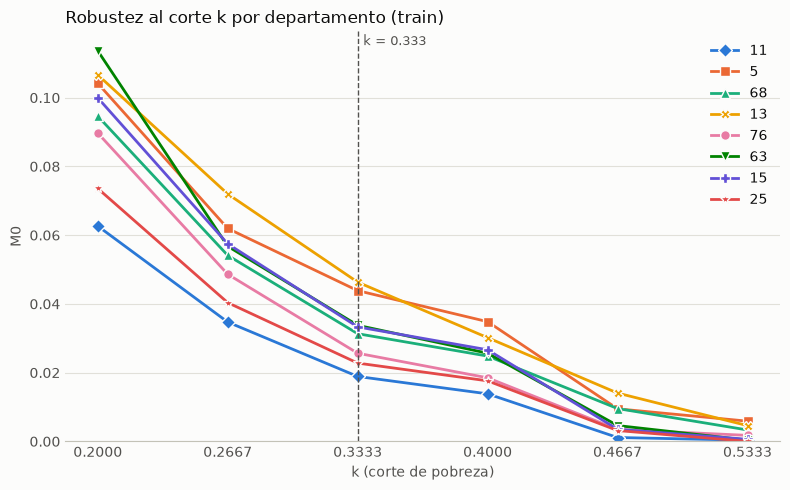

In [132]:
n_dep = (
    train_dep.groupby("P1_DEPARTAMENTO").size().sort_values(ascending=False)
)
validos = n_dep[n_dep >= 300].index
ks = [3 / 15, 4 / 15, 5 / 15, 6 / 15, 7 / 15, 8 / 15]
dom_dep = IPM.dominancia_k(train_dep, ipm.w_, ks=ks, grupo="P1_DEPARTAMENTO")
dom_dep = dom_dep.loc[validos]
fig = IPM.grafico_dominancia(
    dom_dep.loc[validos[:8]],
    titulo="Robustez al corte k por departamento (train)",
)

In [133]:
dom_rango = dom_dep[[3 / 15, 4 / 15, 5 / 15, 6 / 15]]
pares = list(itertools.combinations(dom_rango.index, 2))
robustos = sum(
    ((dom_rango.loc[a] - dom_rango.loc[b]) >= 0).all()
    or ((dom_rango.loc[a] - dom_rango.loc[b]) <= 0).all()
    for a, b in pares
)
print(
    f"{robustos} de {len(pares)} pares sin cruce ({robustos / len(pares):.0%})"
)

417 de 528 pares sin cruce (79%)


Note como independientemente de los umbrales del corte 2 (k) los $M_0$ mantienen, por lo general, su ordenamiento suponiendo esto una robustes de las metricas calculadas frente al k, por lo tanto es un indicio fuerte para aceptar el uso del mismo k que el DANE reporta.

Si bien hay ciertas variaciones ligeras en el ordenamiento no son abismales, ademas esto si permite afirmar que independientemente del k los grupos se rankean de manera similar, esta afirmacion es mas fuerte que la del paper ya que ataca un hueco que el propio autor ataco y es que los grupos eran aleatorios, el equipo al segmentar por grupos reales (en esta oportunidad departamentos) se puede afirmar lo anteriormente dicho.

Todo este analisis se limita al rango acotado de 3/15 a 6/15.

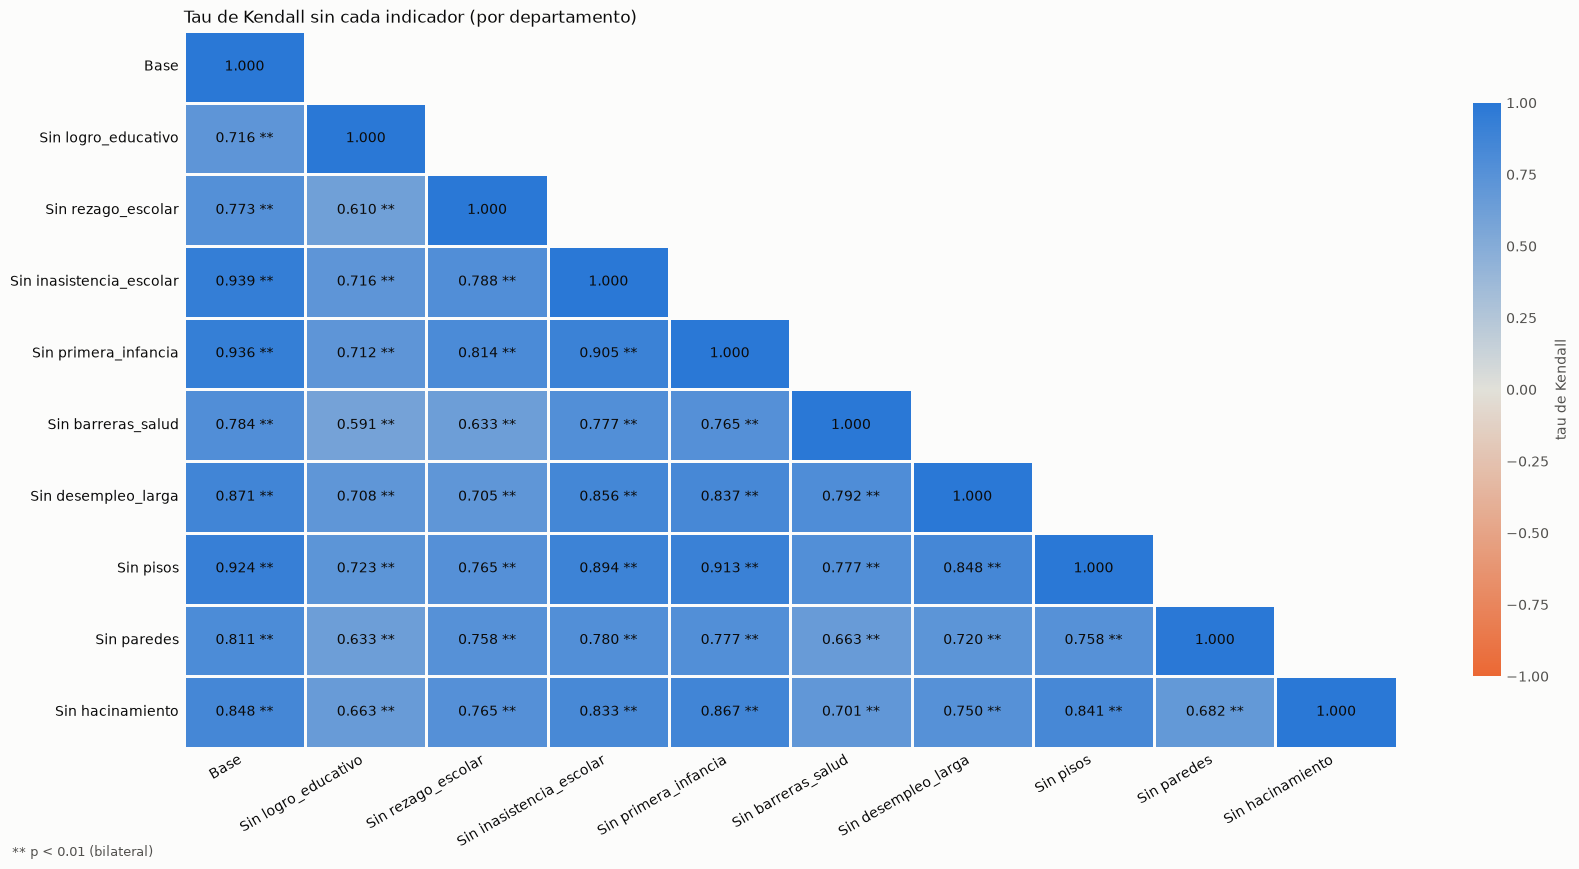

In [134]:
train_val = train_dep[train_dep["P1_DEPARTAMENTO"].isin(validos)]
w = ipm.w_

esq_ind = IPM.esquemas_sin_indicador(w, ipm.indicadores_)
tau_ind, p_ind, m0_ind = IPM.kendall_esquemas(
    train_val, esq_ind, grupo="P1_DEPARTAMENTO"
)

fig = IPM.grafico_kendall(
    tau_ind,
    p_ind,
    titulo="Tau de Kendall sin cada indicador (por departamento)",
)

Note como independientemente de que indicador se elimine el veredicto de los procesos de corte estan altamente correlacionados, por lo tanto es un indicio mas que se apoya la fortaleza de nuestro enfoque alternativo fretne al del DANE (no se puede afirmar que es peor o mejor hasta realizar una comparacion directa).

> Nota: en este y el siguiente grafico el hecho de tener asteriscos o no indica si la asociacion es significativa, esto mediante los p-valores de kendall, en ambos casos bajo un $\alpha = 0.01$

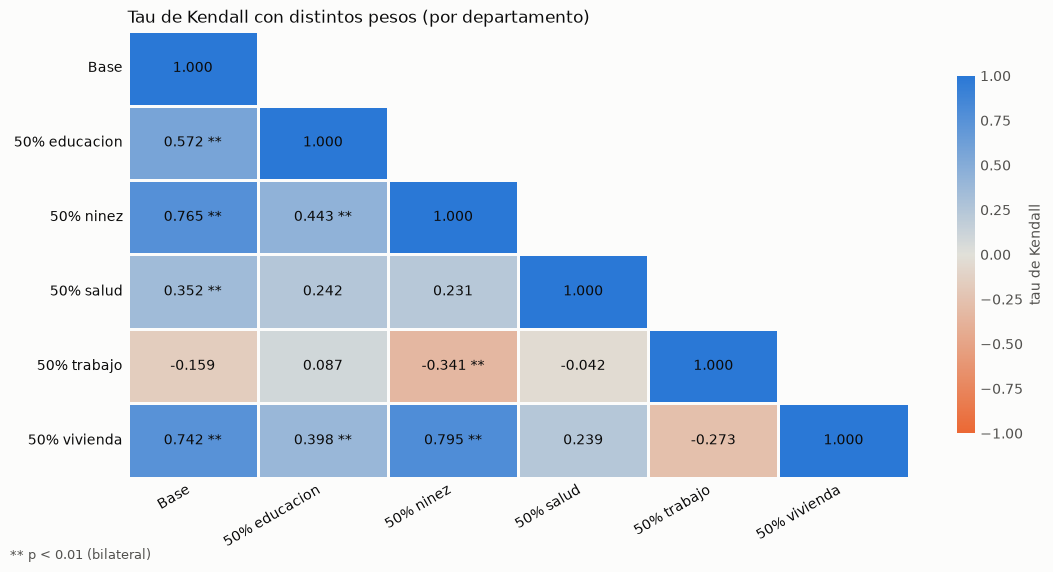

In [135]:
esq_pes = IPM.esquemas_peso_dimension(w, ipm.indicadores_, peso=0.5)
tau_pes, p_pes, m0_pes = IPM.kendall_esquemas(
    train_val, esq_pes, grupo="P1_DEPARTAMENTO"
)

fig = IPM.grafico_kendall(
    tau_pes,
    p_pes,
    titulo="Tau de Kendall con distintos pesos (por departamento)",
)

Si bien en algunos esquemas alternativos de peso (50% del peso en una sola dimension), las conslusiones del vector objetivo estan correlacionadas de manera fuerte, en otras tantas esto no ocurre, por lo que existe el riesgo de que el esquema de pesaje determine en una u otra medida los resultados del corte.

Dicho esto se puede considerar la robustes del corte aceptable, incluso mejor que la reportada por el paper (exepto en la robustes frente a los pesajes), esto a pesar de usar un equema alternativo al DANE. Sin embargo es necesario reconocer la baja robustes que mostro el corte aplicado respecto a los esquemas de pesaje entre dimensiones, por lo que en ese factor si se debe asumir esa falta de robustes aunque el paper original lo considere robusto.

> Nota: adicionalmente los analisis del equipo son mas fuertes que los del paper al agrupar usando grupos fisicos en lugar de aleatorios (una de las limitaciones informadas por el autor).

#### Comparacion rapida contra el DANE

In [136]:
ipm_dane = IPM()
ipm_dane.fit(df_ciudades)

,indicadores,None
,caracteristicas,None
,w,None
,k,None
,codigos,None
,caracteristicas_nan,False
,claves_hogar,"('DIRECTORIO', ...)"
,col_peso,'FEX_C'
,col_clase,'CLASE'
Name,Type,Value
caracteristicas_,list,[]


In [137]:
ipm_dane.w_

{'logro_educativo': np.float64(0.1),
 'analfabetismo': np.float64(0.1),
 'rezago_escolar': np.float64(0.05),
 'inasistencia_escolar': np.float64(0.05),
 'primera_infancia': np.float64(0.05),
 'trabajo_infantil': np.float64(0.05),
 'sin_aseguramiento': np.float64(0.1),
 'barreras_salud': np.float64(0.1),
 'desempleo_larga': np.float64(0.1),
 'trabajo_informal': np.float64(0.1),
 'agua': np.float64(0.04),
 'excretas': np.float64(0.04),
 'pisos': np.float64(0.04),
 'paredes': np.float64(0.04),
 'hacinamiento': np.float64(0.04)}

In [138]:
hogares_dane = ipm_dane.transform(df_ciudades)

In [139]:
hogares_dane

,DIRECTORIO,SECUENCIA_P,PESO,logro_educativo,analfabetismo,rezago_escolar,inasistencia_escolar,primera_infancia,trabajo_infantil,sin_aseguramiento,barreras_salud,desempleo_larga,trabajo_informal,agua,excretas,pisos,paredes,hacinamiento,C,POBRE
0,8369550,1,1888.527605,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0.05,0
1,8369551,1,308.854319,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0.20,0
2,8369552,1,2142.581195,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0.15,0
3,8369553,1,806.929968,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0.30,0
4,8369554,1,707.898884,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0.30,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44346,8489484,1,12.997974,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0.14,0
44347,8489485,1,19.496961,0,0,0,0,1,0,0,0,0,1,0,1,0,0,1,0.23,0
44348,8489486,1,12.997974,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0.14,0
44349,8489487,1,51.343437,0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0.19,0


In [140]:
train_dane = hogares_dane.merge(df_train[claves], on=claves, how="inner")

# 3. Pegar el departamento y quedarse con los mismos departamentos válidos
dep = df_ciudades.groupby(claves)["P1_DEPARTAMENTO"].first().reset_index()
train_dane = train_dane.merge(dep, on=claves, how="left")
train_dane_val = train_dane[train_dane["P1_DEPARTAMENTO"].isin(validos)]

w_dane = ipm_dane.w_

DANE: 389 de 528 pares sin cruce (74%)


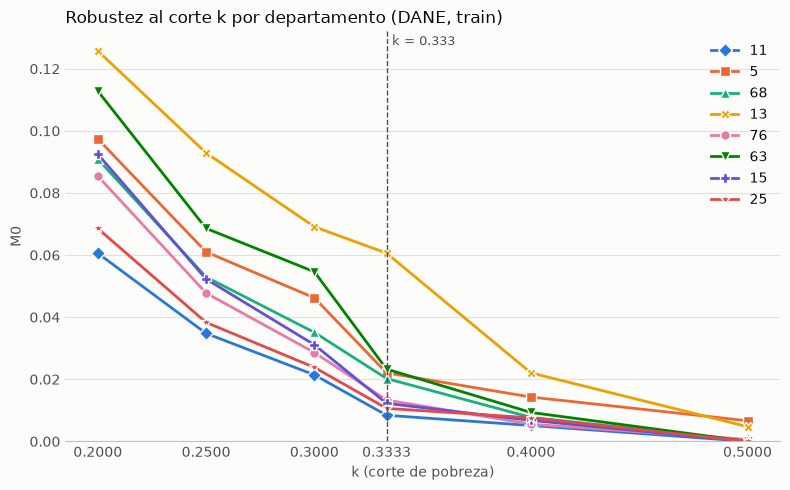

In [141]:
ks_dane = [0.2, 0.25, 0.3, 5 / 15, 0.4, 0.5]
dom_dane = IPM.dominancia_k(
    train_dane_val, w_dane, ks=ks_dane, grupo="P1_DEPARTAMENTO"
)

fig = IPM.grafico_dominancia(
    dom_dane.loc[validos[:8]],
    titulo="Robustez al corte k por departamento (DANE, train)",
)
# Proporción de pares de departamentos sin cruce
pares = list(itertools.combinations(dom_dane.index, 2))
robustos = sum(
    ((dom_dane.loc[a] - dom_dane.loc[b]) >= 0).all()
    or ((dom_dane.loc[a] - dom_dane.loc[b]) <= 0).all()
    for a, b in pares
)
pct = robustos / len(pares)
print(f"DANE: {robustos} de {len(pares)} pares sin cruce ({pct:.0%})")

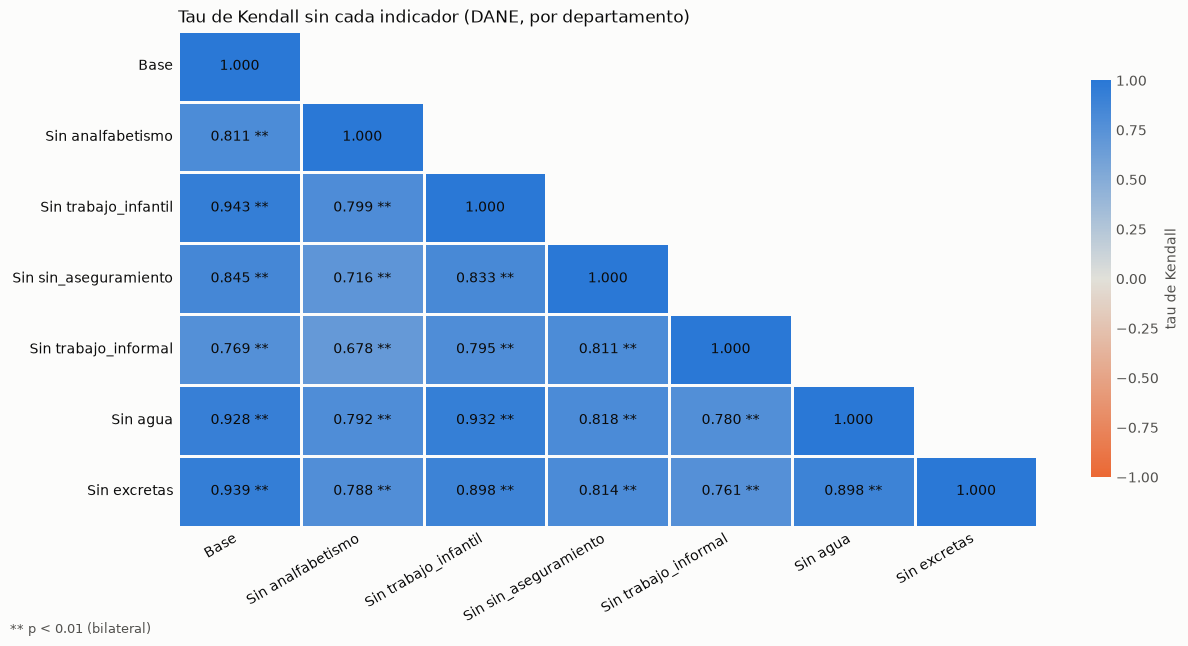

In [142]:
esq_ind_dane = IPM.esquemas_sin_indicador(
    w_dane, ipm_dane.indicadores_, quitar=INDICADORES_ELIMINADOS
)
tau_ind_dane, p_ind_dane, m0_ind_dane = IPM.kendall_esquemas(
    train_dane_val, esq_ind_dane, grupo="P1_DEPARTAMENTO"
)

fig = IPM.grafico_kendall(
    tau_ind_dane,
    p_ind_dane,
    titulo="Tau de Kendall sin cada indicador (DANE, por departamento)",
)

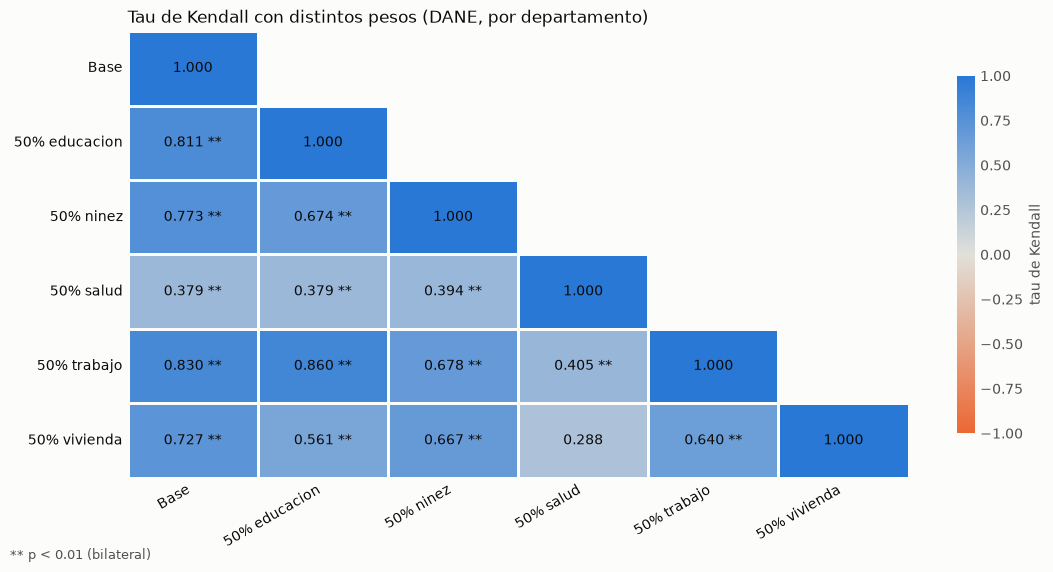

In [143]:
esq_pes_dane = IPM.esquemas_peso_dimension(
    w_dane, ipm_dane.indicadores_, peso=0.5
)
tau_pes_dane, p_pes_dane, m0_pes_dane = IPM.kendall_esquemas(
    train_dane_val, esq_pes_dane, grupo="P1_DEPARTAMENTO"
)

fig = IPM.grafico_kendall(
    tau_pes_dane,
    p_pes_dane,
    titulo="Tau de Kendall con distintos pesos (DANE, por departamento)",
)

In [144]:
pd.DataFrame(
    {
        "Modificado": tau_pes["Base"],
        "DANE": tau_pes_dane["Base"],
    }
).round(3)

,Modificado,DANE
Base,1.000,1.000
50% educacion,0.572,0.811
50% ninez,0.765,0.773
50% salud,0.352,0.379
50% trabajo,-0.159,0.830
50% vivienda,0.742,0.727


Por lo general los resultados de robustes no difieren mucho mas alla de diferencias puntuales (que se consideran como un efecto de limitantes de la investigación), y una diferencia grande, recorriendo estas grafico a grafico se tiene:
- En el grafico que evalua la **robustes ante el corte K** la separacion entre grupos se ve mas marcada en el esquema del DANE no obstante en dicho esquema son mas las parejas que se cruzan en el mismo rango, aunque dicho cambio no es mucho (79% sin cruces en el esquema propuesto vs 74% en el del DANE).
- En el grafico que evalua la **robustes ante la falta de indicadores** el enfoque del DANE dada la mayor cantidad de estos se ve menos afectado por la ausencia de uno, por lo tanto las correlaciones de kendall entre los vectores tales que cada componente contiene los $M_0$ de cada departamentones mas fuerte, es decir los $M_0$ de los departamentos se relacionan bien sin importar que se excuyan indicadores.
- En el grafico que evalua la robustes ante el esquema de pesaje se da la mayor diferecia, esto ya que en el esquema propuesto la mayoria de correlaciones entre vectores resultantes son debiles, mientras que con el esquema del DANE muchas mas son las correlaciones fuertes, esto posiblemente se deba a que hay dimensiones con tan solo un indicador lo que resulta en una sensibilidad alta al pesaje pues estar privado en un solo indicador implicaria estar privado multidimensionalmente (0.5 > 0.3333333).
A pesar de que las correlaciones por lo general son debiles (en el esquema propuesto), son mas fuertes en general con lo que da la base, es decir que se correlacionan de buena manera con lo que daria la base, por lo tanto es relativamente robusto respecto a la base.

# EDA

## Eliminar columnas de las que se deriva el calculo de la target y evaluar calidad general.
Tambien se evaluan las correlaciones contra los indicadores que si se usaron para evitar fuga o se consientes de la limitación tecnica.

        - Indicador de personas con agg="any": proporción de miembros
          elegibles que cumplen la condición de privación (0 a 1).
        - Los hogares sin miembros elegibles quedan en NaN.

In [145]:
df_train_features = df_train[ORIGINALES_NUEVAS + ["POBRE"]].copy()

In [146]:
df_train_features.head()

,ORG_analfabetismo,ORG_trabajo_infantil,ORG_sin_aseguramiento,ORG_P8520S5,ORG_P8530,ORG_P8520S3,ORG_P8526,POBRE
0,0.0,0.0,0.0,1,1,1,1,0
1,0.0,NaN,0.0,1,1,1,1,0
2,0.0,0.0,0.0,1,1,1,1,0
4,0.0,NaN,0.0,1,1,1,1,1
5,0.0,NaN,0.0,1,1,1,1,0


In [147]:
for col in df_train_features.columns:
    print(f"col: {col}")
    print(f"    Numero unicos:{df_train_features[col].nunique()}\n")

col: ORG_analfabetismo
    Numero unicos:19

col: ORG_trabajo_infantil
    Numero unicos:4

col: ORG_sin_aseguramiento
    Numero unicos:22

col: ORG_P8520S5
    Numero unicos:2

col: ORG_P8530
    Numero unicos:10

col: ORG_P8520S3
    Numero unicos:2

col: ORG_P8526
    Numero unicos:6

col: POBRE
    Numero unicos:2



In [148]:
df_train_features.isna().mean()

ORG_analfabetismo        0.000032
ORG_trabajo_infantil     0.791746
ORG_sin_aseguramiento    0.000000
ORG_P8520S5              0.000000
ORG_P8530                0.000000
ORG_P8520S3              0.000000
ORG_P8526                0.000000
POBRE                    0.000000
dtype: float64

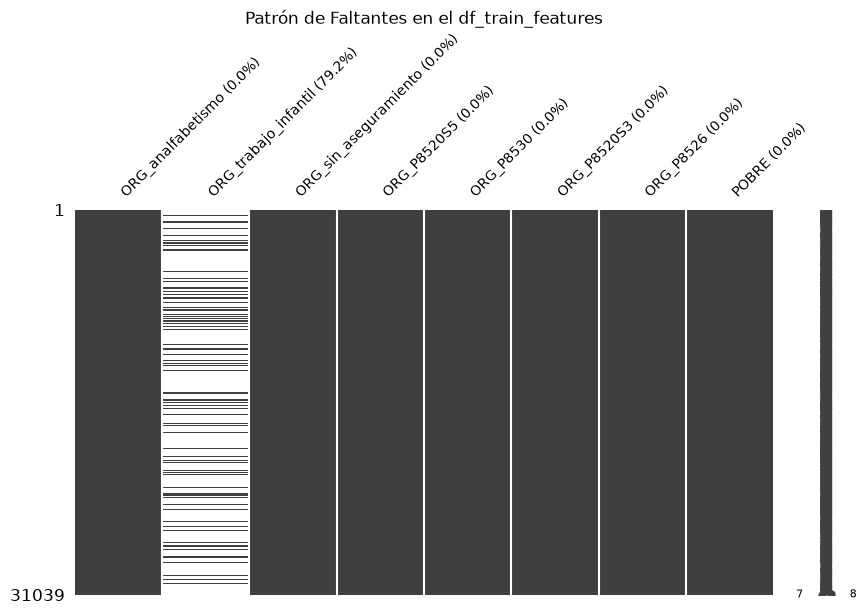

In [149]:
n_cols = len(df_train_features.columns)
ancho = max(10, int(n_cols * 0.35))
alto = 5

tamano_letra = max(6, 10 - n_cols // 10)

# Porcentaje de nulos por columna
pct_nulos = df_train_features.isnull().mean() * 100

try:
    ax = (
        msno.matrix(
            df_train_features, figsize=(ancho, alto), fontsize=tamano_letra
        )
        or plt.gca()
    )
    plt.title("Patrón de Faltantes en el df_train_features")

    if len(ax.get_xticks()) == n_cols:
        ax.set_xticks(range(n_cols))
        ax.set_xticklabels(
            [
                f"{c} ({p:.1f}%)"
                for c, p in zip(df_train_features.columns, pct_nulos)
            ],
            rotation=45,
            ha="left",
            fontsize=tamano_letra,
        )

    plt.show()

except Exception:
    plt.figure(figsize=(ancho, alto))
    missing_pattern = df_train_features.isnull()

    plt.imshow(missing_pattern.astype(int), aspect="auto", cmap="RdYlGn_r")

    plt.xticks(
        ticks=range(n_cols),
        labels=[
            f"{c} ({p:.1f}%)"
            for c, p in zip(missing_pattern.columns, pct_nulos)
        ],
        rotation=90,
        fontsize=tamano_letra,
        ha="center",
    )
    plt.yticks([])
    plt.title("Patrón de Faltantes (blanco = faltante)")
    plt.colorbar(label="1=Faltante, 0=Presente")

    plt.tight_layout()  # Evita que las etiquetas se corten abajo
    plt.show()

Dado que los nulos son algo natural del contexto, pues son hogares a los que no les aplica ese indicador, se imputan con 0 y se agrega un indicador de nulidad, que puede ser útil a futuro. El imputador se ajusta **solo con train**: con `add_indicator=True` aprende en qué columnas hay nulos, así que validación se transforma después con `imputador.transform`, sin volver a ajustarlo.

In [150]:
imputador = SimpleImputer(
    strategy="constant", fill_value=0, add_indicator=True
)

In [151]:
df_train_features_imputed = imputador.fit_transform(df_train_features)
df_train_features_imputed

,ORG_analfabetismo,ORG_trabajo_infantil,ORG_sin_aseguramiento,ORG_P8520S5,ORG_P8530,ORG_P8520S3,ORG_P8526,POBRE,missingindicator_ORG_analfabetismo,missingindicator_ORG_trabajo_infantil
0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0
1,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0
2,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0
4,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0
5,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...
44336,0.0,0.0,0.0,1.0,2.0,2.0,2.0,0.0,0.0,1.0
44337,0.0,0.0,0.0,1.0,2.0,2.0,2.0,0.0,0.0,1.0
44338,0.0,0.0,0.0,1.0,2.0,2.0,2.0,0.0,0.0,1.0
44339,0.0,0.0,0.0,1.0,2.0,2.0,2.0,0.0,0.0,1.0


In [152]:
df_train_features_imputed.isna().mean()

ORG_analfabetismo                        0.0
ORG_trabajo_infantil                     0.0
ORG_sin_aseguramiento                    0.0
ORG_P8520S5                              0.0
ORG_P8530                                0.0
ORG_P8520S3                              0.0
ORG_P8526                                0.0
POBRE                                    0.0
missingindicator_ORG_analfabetismo       0.0
missingindicator_ORG_trabajo_infantil    0.0
dtype: float64

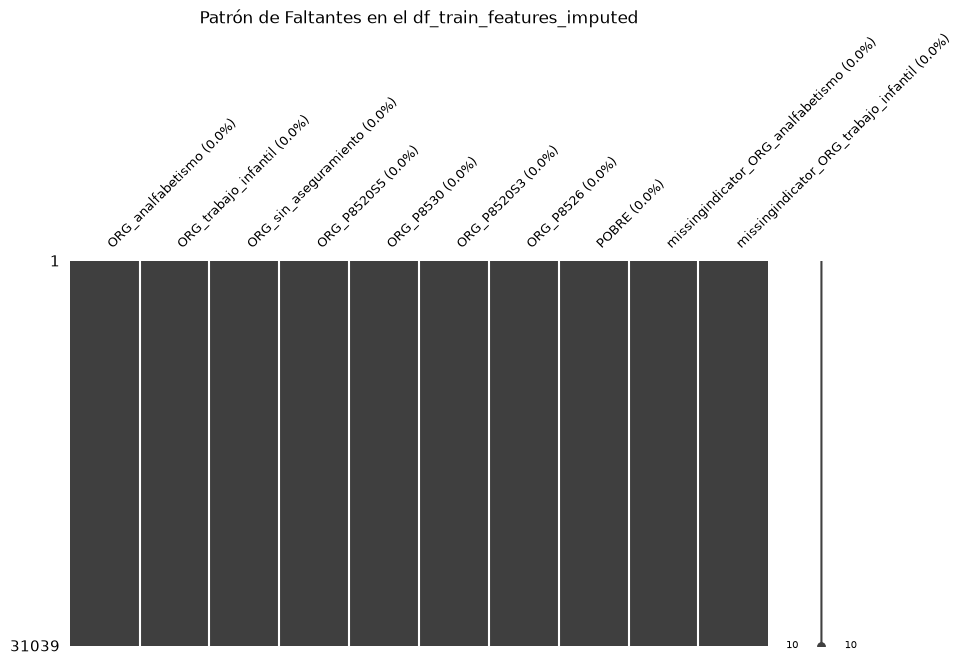

In [153]:
n_cols = len(df_train_features_imputed.columns)
ancho = max(10, int(n_cols * 0.35))
alto = 5

tamano_letra = max(6, 10 - n_cols // 10)

# Porcentaje de nulos por columna
pct_nulos = df_train_features_imputed.isnull().mean() * 100

try:
    ax = (
        msno.matrix(
            df_train_features_imputed,
            figsize=(ancho, alto),
            fontsize=tamano_letra,
        )
        or plt.gca()
    )
    plt.title("Patrón de Faltantes en el df_train_features_imputed")

    if len(ax.get_xticks()) == n_cols:
        ax.set_xticks(range(n_cols))
        ax.set_xticklabels(
            [
                f"{c} ({p:.1f}%)"
                for c, p in zip(df_train_features_imputed.columns, pct_nulos)
            ],
            rotation=45,
            ha="left",
            fontsize=tamano_letra,
        )

    plt.show()

except Exception:
    plt.figure(figsize=(ancho, alto))
    missing_pattern = df_train_features_imputed.isnull()

    plt.imshow(missing_pattern.astype(int), aspect="auto", cmap="RdYlGn_r")

    plt.xticks(
        ticks=range(n_cols),
        labels=[
            f"{c} ({p:.1f}%)"
            for c, p in zip(missing_pattern.columns, pct_nulos)
        ],
        rotation=90,
        fontsize=tamano_letra,
        ha="center",
    )
    plt.yticks([])
    plt.title("Patrón de Faltantes (blanco = faltante)")
    plt.colorbar(label="1=Faltante, 0=Presente")

    plt.tight_layout()  # Evita que las etiquetas se corten abajo
    plt.show()

### Evaluar correlacion de los indicadores que son caracteristicas y los que funcionaron en el corte

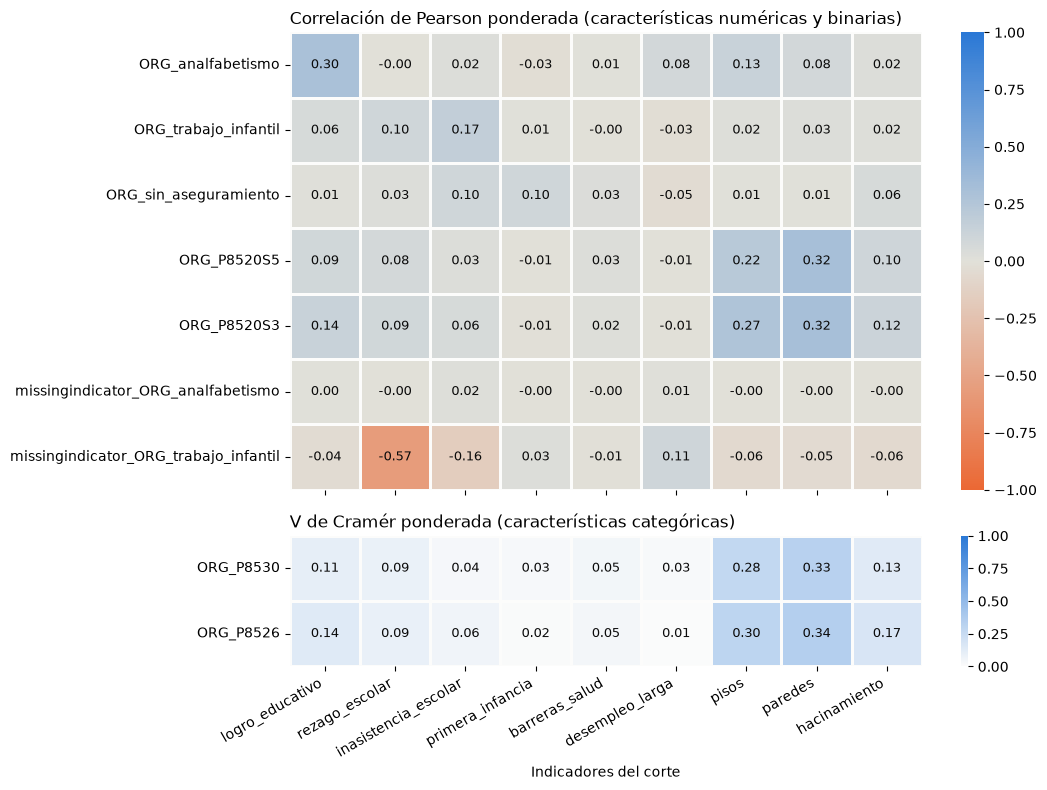

In [154]:
X_prov = df_train_features_imputed.drop(
    columns="POBRE"
)  # POBRE es el objetivo, no una característica
assert X_prov.index.equals(df_train.index), (
    "Las filas de X y df_train no están alineadas"
)

corte = list(ipm.w_)
peso = df_train["PESO"]

numericas = [
    "ORG_analfabetismo",
    "ORG_trabajo_infantil",
    "ORG_sin_aseguramiento",
    "ORG_P8520S5",
    "ORG_P8520S3",
    "missingindicator_ORG_analfabetismo",
    "missingindicator_ORG_trabajo_infantil",
]
categoricas = ["ORG_P8530", "ORG_P8526"]


def pearson_ponderado(x, y, w):
    """Correlación de Pearson ponderada (punto-biserial si y es binaria)."""
    m = x.notna() & y.notna()
    x, y, w = x[m].astype(float), y[m].astype(float), w[m]
    mx, my = np.average(x, weights=w), np.average(y, weights=w)
    cov = np.average((x - mx) * (y - my), weights=w)
    sx = np.sqrt(np.average((x - mx) ** 2, weights=w))
    sy = np.sqrt(np.average((y - my) ** 2, weights=w))
    return cov / (sx * sy) if sx > 0 and sy > 0 else np.nan


def cramer_v_ponderado(x, y, w):
    """V de Cramér con la tabla de contingencia ponderada por PESO."""
    m = x.notna() & y.notna()
    tabla = pd.crosstab(x[m], y[m], values=w[m], aggfunc="sum").fillna(0)
    k = min(tabla.shape) - 1
    if k == 0:
        return np.nan
    chi2 = chi2_contingency(tabla, correction=False)[0]
    return np.sqrt(chi2 / (tabla.values.sum() * k))


r = pd.DataFrame(
    [
        [pearson_ponderado(X_prov[a], df_train[b], peso) for b in corte]
        for a in numericas
    ],
    index=numericas,
    columns=corte,
)
v = pd.DataFrame(
    [
        [cramer_v_ponderado(X_prov[a], df_train[b], peso) for b in corte]
        for a in categoricas
    ],
    index=categoricas,
    columns=corte,
)

cmap_div = LinearSegmentedColormap.from_list(
    "div", ["#eb6834", "#e1e0d9", "#2a78d6"]
)
cmap_seq = LinearSegmentedColormap.from_list("seq", ["#fcfcfb", "#2a78d6"])

fig, (ax1, ax2) = plt.subplots(
    2,
    1,
    figsize=(11, 8),
    gridspec_kw={"height_ratios": [len(numericas), len(categoricas)]},
)
sns.heatmap(
    r,
    annot=True,
    fmt=".2f",
    cmap=cmap_div,
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=2,
    linecolor="#fcfcfb",
    annot_kws={"color": "#0b0b0b", "fontsize": 9},
    ax=ax1,
)
ax1.set_title(
    "Correlación de Pearson ponderada (características numéricas y binarias)",
    loc="left",
)
ax1.set_xticklabels([])

sns.heatmap(
    v,
    annot=True,
    fmt=".2f",
    cmap=cmap_seq,
    vmin=0,
    vmax=1,
    linewidths=2,
    linecolor="#fcfcfb",
    annot_kws={"color": "#0b0b0b", "fontsize": 9},
    ax=ax2,
)
ax2.set_title(
    "V de Cramér ponderada (características categóricas)", loc="left"
)
plt.setp(ax2.get_xticklabels(), rotation=30, ha="right")

for ax in (ax1, ax2):
    ax.set_ylabel("")
ax2.set_xlabel("Indicadores del corte")
fig.tight_layout()

Note que ninguna de las variables que se le daran al modelo presenta una alta correlación con aquellas varibales que se usaron para realizar el corte que genera la variable (Dual Cutoff). Por lo tanto este diseño no supone ningun tipo de fuga de información. La unica excepcion radica en ORG_trabajo_infantil, que se correlaciona con rezago escolar (r = −0,57). Esta relación se debe a la composición del hogar: los hogares sin personas de 12 a 17 años tienen menos miembros en edad de presentar rezago escolar. No constituye una fuga de información, sin embargo si es una cierta asociacion que se reporta como riesgo metodologico.

> Nota: El calculo es ponderado ya que el diseño del DANE al ser un muestreo estratificado por conglomerados se debe mantener el factor de extension PESO.

In [155]:
NOMBRES_ORG = {
    # ¿Tiene acueducto? (1 = sí, 2 = no)
    "ORG_P8520S5": "ORG_acueducto",
    # Fuente del agua para preparar alimentos (1 a 10)
    "ORG_P8530": "ORG_fuente_agua_cocinar",
    # ¿Tiene alcantarillado? (1 = sí, 2 = no)
    "ORG_P8520S3": "ORG_alcantarillado",
    # Tipo de servicio sanitario (1 a 6)
    "ORG_P8526": "ORG_servicio_sanitario",
}

df_train_features_imputed = df_train_features_imputed.rename(
    columns=NOMBRES_ORG
)

In [156]:
df_test = df_test.rename(columns=NOMBRES_ORG)
df_val = df_val.rename(columns=NOMBRES_ORG)
df_train_features = df_train_features.rename(columns=NOMBRES_ORG)

In [157]:
ORIGINALES_RENOMBRADAS = [NOMBRES_ORG.get(c, c) for c in ORIGINALES_NUEVAS]

## Analisis descriptivo basico

In [158]:
df_train_features_imputed.info()

<class 'pandas.DataFrame'>
Index: 31039 entries, 0 to 44340
Data columns (total 10 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   ORG_analfabetismo                      31039 non-null  float64
 1   ORG_trabajo_infantil                   31039 non-null  float64
 2   ORG_sin_aseguramiento                  31039 non-null  float64
 3   ORG_acueducto                          31039 non-null  float64
 4   ORG_fuente_agua_cocinar                31039 non-null  float64
 5   ORG_alcantarillado                     31039 non-null  float64
 6   ORG_servicio_sanitario                 31039 non-null  float64
 7   POBRE                                  31039 non-null  float64
 8   missingindicator_ORG_analfabetismo     31039 non-null  float64
 9   missingindicator_ORG_trabajo_infantil  31039 non-null  float64
dtypes: float64(10)
memory usage: 2.6 MB


In [159]:
for col in df_train_features_imputed.columns:
    print(f"col: {col}")
    print(f"    Numero unicos:{df_train_features_imputed[col].nunique()}\n")

col: ORG_analfabetismo
    Numero unicos:19

col: ORG_trabajo_infantil
    Numero unicos:4

col: ORG_sin_aseguramiento
    Numero unicos:22

col: ORG_acueducto
    Numero unicos:2

col: ORG_fuente_agua_cocinar
    Numero unicos:10

col: ORG_alcantarillado
    Numero unicos:2

col: ORG_servicio_sanitario
    Numero unicos:6

col: POBRE
    Numero unicos:2

col: missingindicator_ORG_analfabetismo
    Numero unicos:2

col: missingindicator_ORG_trabajo_infantil
    Numero unicos:2



In [160]:
ETIQUETAS = {
    "ORG_acueducto": {1: "Sí", 2: "No"},
    "ORG_alcantarillado": {1: "Sí", 2: "No"},
    "ORG_fuente_agua_cocinar": {
        1: "Acueducto público",
        2: "Acueducto comunal o veredal",
        3: "Pozo con bomba",
        4: "Pozo sin bomba, aljibe, jagüey o barreno",
        5: "Agua lluvia",
        6: "Río, quebrada, manantial o nacimiento",
        7: "Pila pública",
        8: "Carrotanque",
        9: "Aguatero",
        10: "Agua embotellada o en bolsa",
    },
    "ORG_servicio_sanitario": {
        1: "Inodoro conectado a alcantarillado",
        2: "Inodoro conectado a pozo séptico",
        3: "Inodoro sin conexión",
        4: "Letrina",
        5: "Inodoro con descarga directa a fuentes de agua (bajamar)",
        6: "No tiene servicio sanitario",
    },
    "POBRE": {0: "No pobre", 1: "Pobre"},
    "missingindicator_ORG_analfabetismo": {
        0: "Aplica",
        1: "Sin personas de 15 años o más",
    },
    "missingindicator_ORG_trabajo_infantil": {
        0: "Aplica",
        1: "Sin personas de 12 a 17 años",
    },
}

df_eda = df_train_features_imputed.copy()
for col, mapa in ETIQUETAS.items():
    # round + Int64 por si la imputación dejó los códigos como 1.0, 2.0...
    df_eda[col] = df_eda[col].round().astype("Int64").map(mapa)

df_eda["PESO"] = df_train["PESO"]  # mismo índice que df_train

<Axes: title={'left': 'Distribución de Pobre'}, xlabel='Pobre', ylabel='Conteo'>

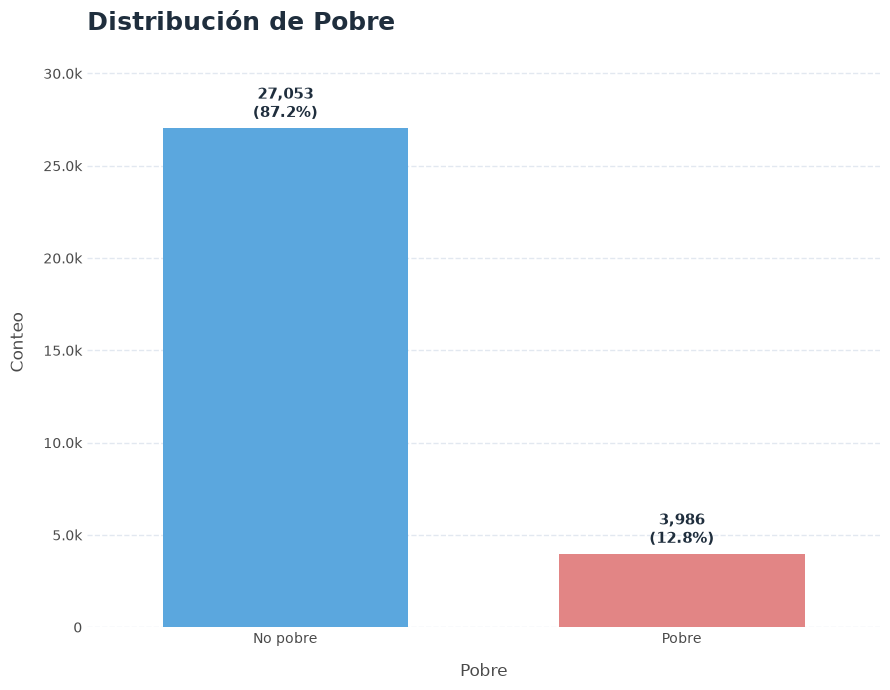

In [161]:
fancy_bars(df_eda, "POBRE", labels="both")

Observe como se esta lideando con un problema altamente desbalanceado, eso abre las puertas a una futura necesidad de utilizar metodos de rebalanceo como SMOTE o pesaje.

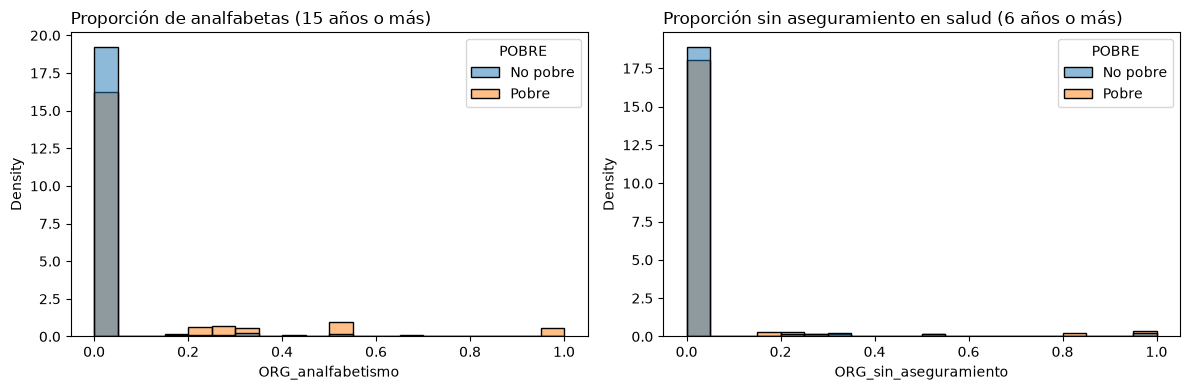

In [162]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

aplica = df_eda["missingindicator_ORG_analfabetismo"] == "Aplica"
sns.histplot(
    data=df_eda[aplica],
    x="ORG_analfabetismo",
    hue="POBRE",
    weights="PESO",
    stat="density",
    common_norm=False,
    bins=20,
    ax=ejes[0],
)
ejes[0].set_title("Proporción de analfabetas (15 años o más)", loc="left")

sns.histplot(
    data=df_eda,
    x="ORG_sin_aseguramiento",
    hue="POBRE",
    weights="PESO",
    stat="density",
    common_norm=False,
    bins=20,
    ax=ejes[1],
)
ejes[1].set_title(
    "Proporción sin aseguramiento en salud (6 años o más)", loc="left"
)

fig.tight_layout()

Note como la mayoria de hogares si que tienen aseguramiento en la salud y no tienen miembros analfabetas, sin embargo eso no implica no pobreza, adicionalmente son pocos los hogares con todos sus miebros analfabetas, no obstante es interesante observar que esto ocurre en los cascos urbanos.

In [163]:
cols_barras_valor = ["ORG_trabajo_infantil"]

cols_categoricas = ["ORG_fuente_agua_cocinar", "ORG_servicio_sanitario"]

cols_binarias = [
    "ORG_acueducto",
    "ORG_alcantarillado",
    "missingindicator_ORG_analfabetismo",
    "missingindicator_ORG_trabajo_infantil",
]

cols_sin_histograma = cols_barras_valor + cols_categoricas + cols_binarias

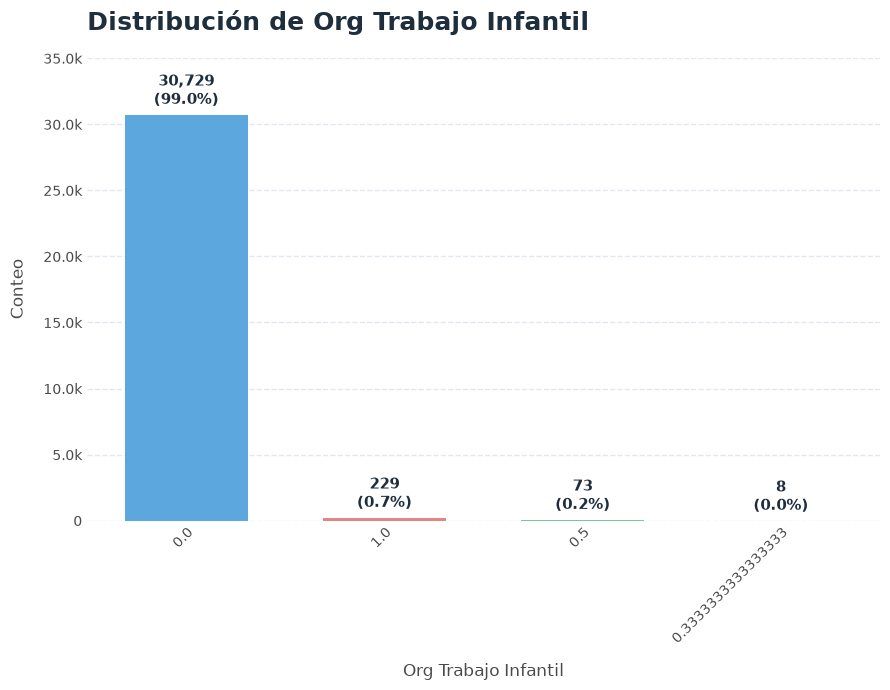

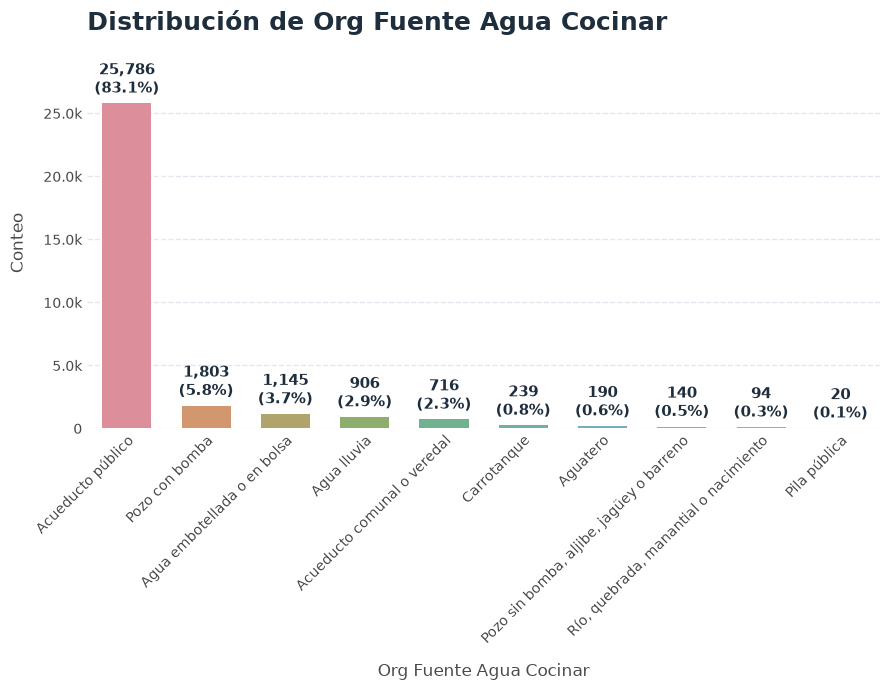

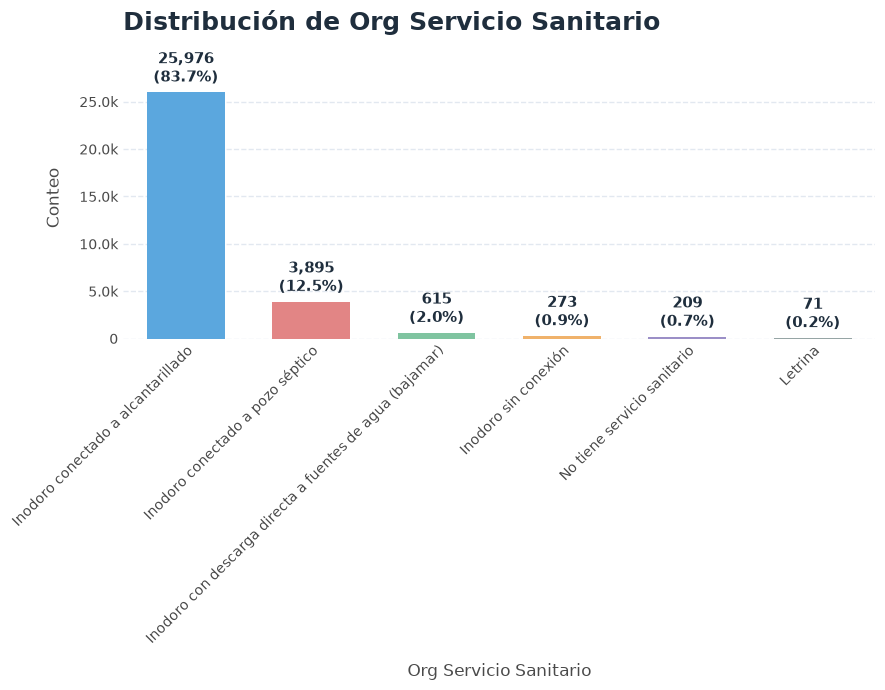

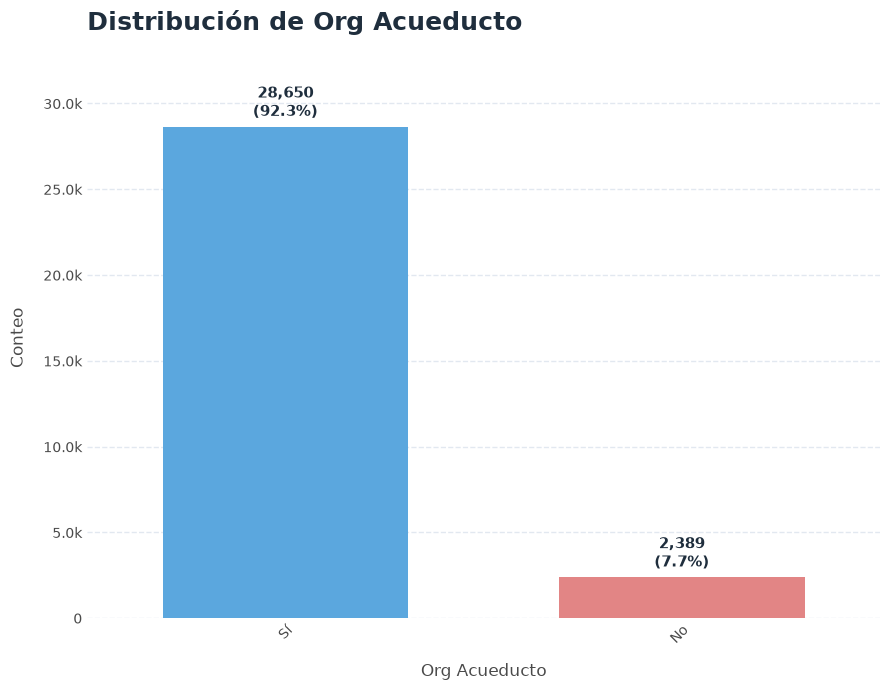

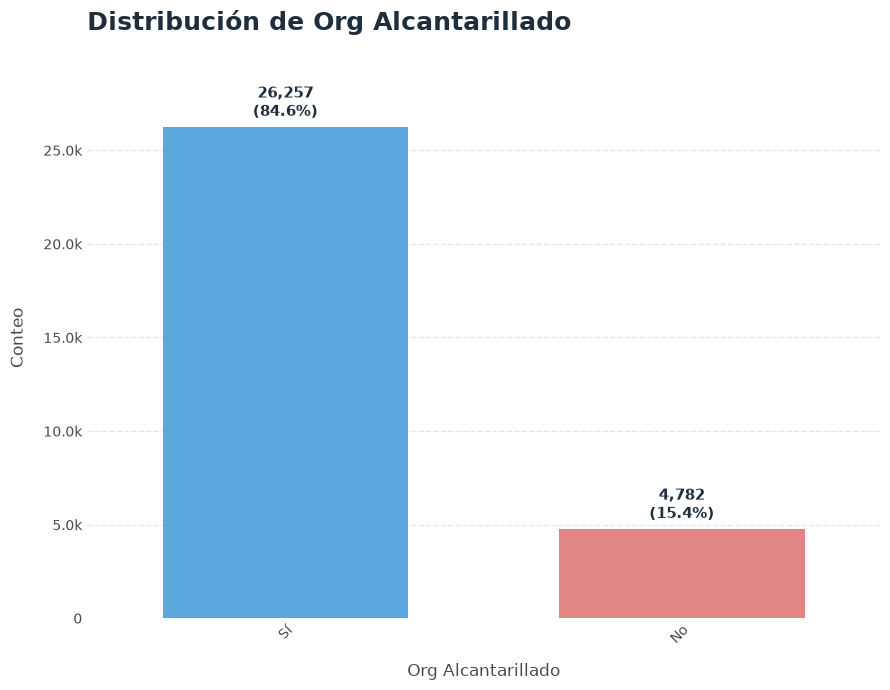

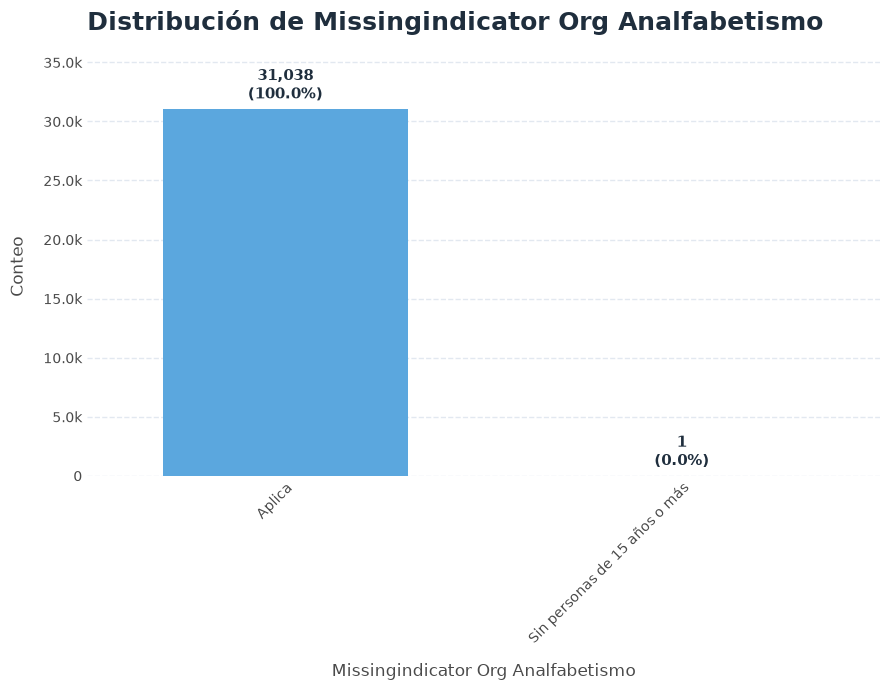

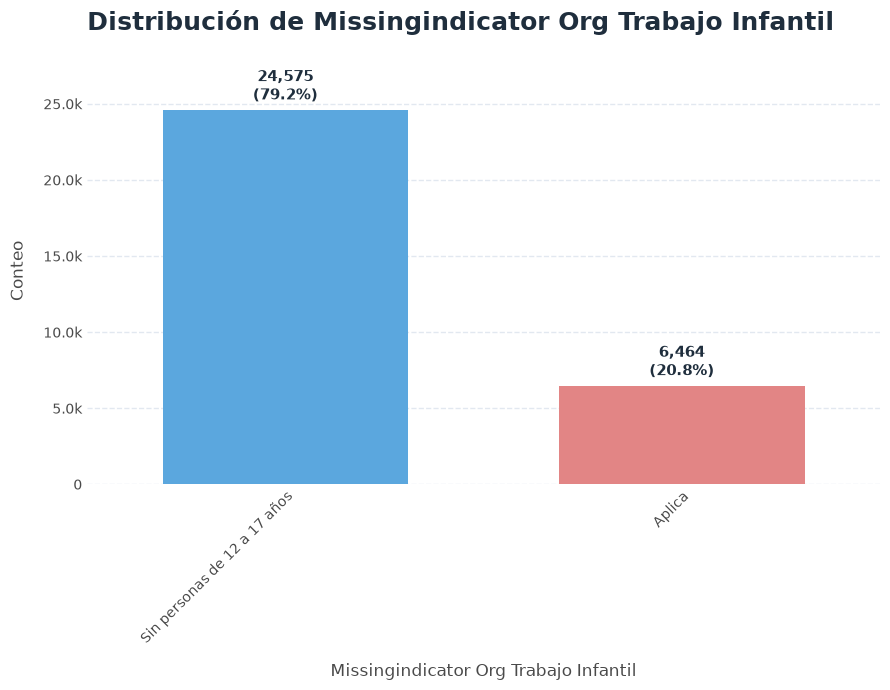

In [164]:
for col in cols_sin_histograma:
    fancy_bars(df_eda, col, rot=45, labels="both")

La gran mayoria de la muestra utiliza el acueducto publico como principal fuente hidrica para cocinar sus alimentos, seguido del pozo con bomba y la fuente menos usada es la pila publica.

La mayoria de la muestra (recuerde que son solo ciudades) tiene un inodoro conectado al alcantarillado y solo una pequeña parte de esta misma tiene letrina.

Asimismo la gran parte de la muestra tiene acceso a el acueducto publico y alcantarillado.

Practicamente toda la muestra aplica al indicador de analfabetismo (eso no quiere decir que los miebros sean analfabetos, solo que aplican a ser evaluados en la privacion, el hecho de ser analfabetos viene de `ORG_analfabetismo`), y gran parte de la muestra no tiene personas de 12 a 17 años dentro del hogar, por lo que no aplican a ser evaluados en el indicador `Trabajo infantil`.

Como pasos de procesamiento se plantea que las variables con multiples clases de codifiquen considerando su orden intrinsico de mejor a peor, por ejemplo lo que supondria una mejor calidad de vida es tener un retrete conectado al sistmea y lo peor tener por ejemplo una letrina, esa codificación se lleva a cabo en pasos posteriores.

## Analisis bi variado

In [165]:
for col in cols_binarias:
    display(
        pd.crosstab(
            df_eda[col],
            df_eda["POBRE"],
            values=df_eda["PESO"],
            aggfunc="sum",
            normalize="all",
            margins=True,
        ).round(4)
    )

POBRE,No pobre,Pobre,All
ORG_acueducto,,,
No,0.0177,0.0084,0.0261
Sí,0.8923,0.0816,0.9739
All,0.9100,0.0900,1.0000


POBRE,No pobre,Pobre,All
ORG_alcantarillado,,,
No,0.0575,0.0190,0.0765
Sí,0.8525,0.0709,0.9235
All,0.9100,0.0900,1.0000


POBRE,No pobre,Pobre,All
missingindicator_ORG_analfabetismo,,,
Aplica,0.91,0.09,1.0
Sin personas de 15 años o más,0.00,0.00,0.0
All,0.91,0.09,1.0


POBRE,No pobre,Pobre,All
missingindicator_ORG_trabajo_infantil,,,
Aplica,0.2569,0.0360,0.2929
Sin personas de 12 a 17 años,0.6531,0.0539,0.7071
All,0.9100,0.0900,1.0000


In [166]:
discrete_plot_joint(df_eda, "ORG_acueducto", "POBRE", weights="PESO")

Vea que lo mas probable es No ser pobre y tener acueducto, sin embargo si se fija la clase pobre (multidimensionalmente) lo mas comun dentro de esta tambien es tener acueducto

In [167]:
discrete_plot_joint(df_eda, "ORG_alcantarillado", "POBRE", weights="PESO")

Se repite la misma tendencia del grafico anterior.

### Pruebas de hipotesis de dependencia contra la target

In [168]:
hub_pruebas_cat_cat(df_eda, "POBRE", cols_sin_histograma)

,var_base,var_categorica,tabla,n,prueba,estadistico,gl,p_valor,v_cramer,frec_esperada_min,pct_celdas_esp_menor_5,supuesto_frecuencias,supuesto_independencia,detalle_supuestos,decision,conclusion,post_hoc
0,POBRE,ORG_trabajo_infantil,4x2,31039,chi-cuadrado,154.3512,3,0.000000,0.0705,1.03,12.5,sí,no verificable (diseño muestral),frecuencias esperadas suficientes (Cochran),Se rechaza H0,Dependencia: la distribución de una variable c...,"0.0 × Pobre (-, r=-11.63); 0.0 × No pobre (+, ..."
1,POBRE,ORG_fuente_agua_cocinar,10x2,31039,chi-cuadrado,258.9122,9,0.000000,0.0913,2.57,5.0,sí,no verificable (diseño muestral),frecuencias esperadas suficientes (Cochran),Se rechaza H0,Dependencia: la distribución de una variable c...,"Aguatero × Pobre (+, r=8.83); Aguatero × No po..."
2,POBRE,ORG_servicio_sanitario,6x2,31039,chi-cuadrado,510.7780,5,0.000000,0.1283,9.12,0.0,sí,no verificable (diseño muestral),frecuencias esperadas suficientes (Cochran),Se rechaza H0,Dependencia: la distribución de una variable c...,Inodoro conectado a alcantarillado × No pobre ...
3,POBRE,ORG_acueducto,2x2,31039,chi-cuadrado (Yates),169.7830,1,0.000000,0.0741,306.79,0.0,sí,no verificable (diseño muestral),frecuencias esperadas suficientes (Cochran),Se rechaza H0,Dependencia: la distribución de una variable c...,"Sí × No pobre (+, r=13.06); Sí × Pobre (-, r=-..."
4,POBRE,ORG_alcantarillado,2x2,31039,chi-cuadrado (Yates),381.1085,1,0.000000,0.1109,614.10,0.0,sí,no verificable (diseño muestral),frecuencias esperadas suficientes (Cochran),Se rechaza H0,Dependencia: la distribución de una variable c...,"Sí × No pobre (+, r=19.55); Sí × Pobre (-, r=-..."
5,POBRE,missingindicator_ORG_trabajo_infantil,2x2,31039,chi-cuadrado (Yates),68.7155,1,0.000000,0.0472,830.10,0.0,sí,no verificable (diseño muestral),frecuencias esperadas suficientes (Cochran),Se rechaza H0,Dependencia: la distribución de una variable c...,"Sin personas de 12 a 17 años × Pobre (-, r=-8...."
6,POBRE,missingindicator_ORG_analfabetismo,2x2,31039,chi-cuadrado (Yates),1.2336,1,0.266703,0.0148,0.13,50.0,no,no verificable (diseño muestral),2 de 4 celdas con frecuencia esperada < 5 (en ...,No se rechaza H0,Independencia: no hay evidencia de asociación,


Se observa que 6 de 7 caracteristicas dan como resultado evidencia suficiente para afirmar una asociacion categorica con la variable objetivo `POBRE`, la unica caracteristica que no permite afirmar eso (no hay evidencia estadistica suficiente) es `missingindicator_ORG_analfabetismo`, por esto mismo se plantea una seleccion de caractristicas dentro del pipeline de tipo forward con un objetivo de seleccionar 5 variables.

### Recodificación ordinal

`ORG_fuente_agua_cocinar` se reordena de mejor (1) a peor (10) según el esquema de abajo; `ORG_servicio_sanitario` ya viene en ese orden (1 = inodoro conectado al alcantarillado, 6 = sin servicio sanitario). `df_eda` conserva las etiquetas del DANE porque se construyó antes de este paso.

In [169]:
# Fuente del agua de mejor a peor; el valor es el código DANE (P8530)
ORDEN_FUENTE_AGUA = {
    "Acueducto público": 1,
    "Acueducto comunal o veredal": 2,
    "Agua embotellada o en bolsa": 10,
    "Pozo con bomba": 3,
    "Pila pública": 7,
    "Carrotanque": 8,
    "Aguatero": 9,
    "Pozo sin bomba, aljibe, jagüey o barreno": 4,
    "Agua lluvia": 5,
    "Río, quebrada, manantial o nacimiento": 6,
}
# código DANE -> posición (1 = mejor, 10 = peor)
FUENTE_AGUA_ORDINAL = {
    codigo: posicion
    for posicion, codigo in enumerate(ORDEN_FUENTE_AGUA.values(), start=1)
}

df_train_features["ORG_fuente_agua_cocinar"] = df_train["ORG_P8530"].map(
    FUENTE_AGUA_ORDINAL
)

df_train_features_imputed["ORG_fuente_agua_cocinar"] = df_train_features[
    "ORG_fuente_agua_cocinar"
]
assert df_train_features_imputed["ORG_fuente_agua_cocinar"].notna().all()

In [170]:
all(
    df_train_features["ORG_fuente_agua_cocinar"]
    == df_train["ORG_P8530"].map(FUENTE_AGUA_ORDINAL)
)

True

### Correlaciones globales (ponderadas)

In [171]:
ORDINALES = ["ORG_fuente_agua_cocinar", "ORG_servicio_sanitario"]
cols = list(df_train_features_imputed.columns)
peso = df_train["PESO"]

corr_global = pd.DataFrame(
    [
        [
            pearson_ponderado(
                df_train_features_imputed[a],
                df_train_features_imputed[b],
                peso,
            )
            for b in cols
        ]
        for a in cols
    ],
    index=cols,
    columns=cols,
)

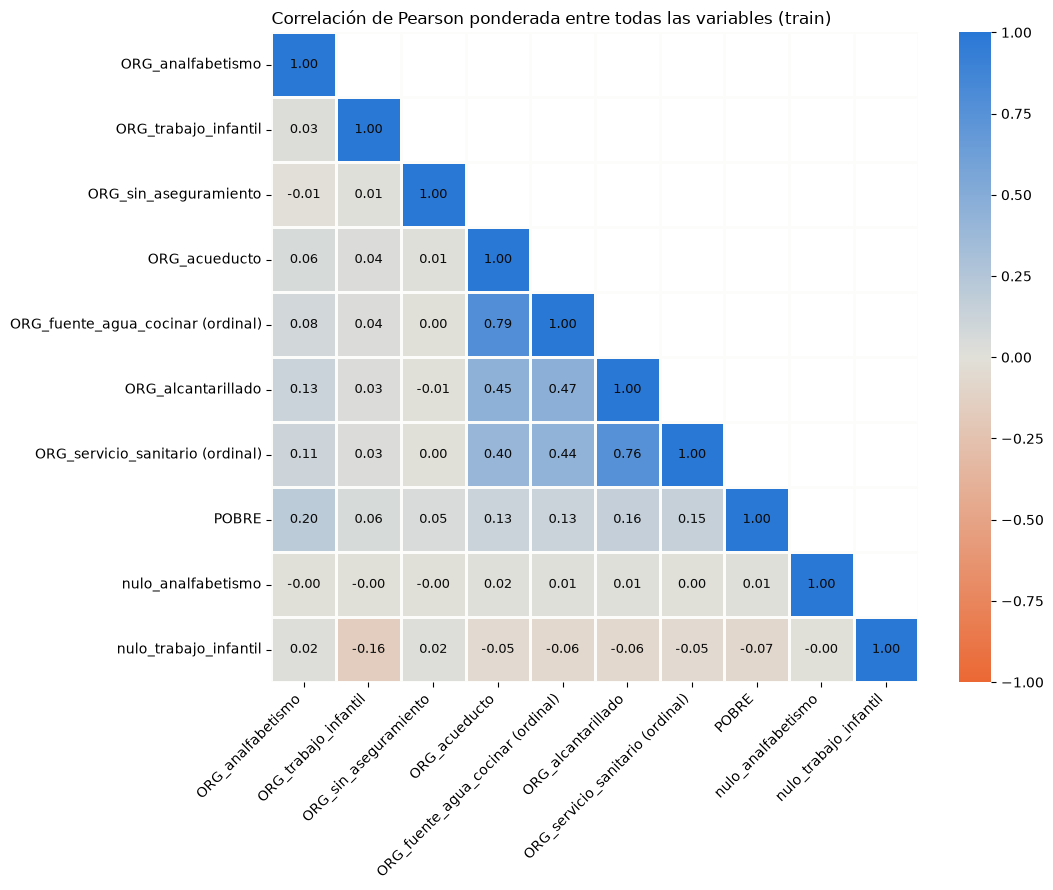

In [172]:
def _etiqueta(col):
    """Acorta los indicadores de nulos y marca las variables ordinales."""
    nombre = col.replace("missingindicator_ORG_", "nulo_")
    return f"{nombre} (ordinal)" if col in ORDINALES else nombre


etiquetas = [_etiqueta(c) for c in cols]
# Solo el triángulo inferior: cada par aparece una vez
mascara = np.triu(np.ones(corr_global.shape, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    corr_global,
    mask=mascara,
    annot=True,
    fmt=".2f",
    cmap=cmap_div,
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=2,
    linecolor="#fcfcfb",
    annot_kws={"color": "#0b0b0b", "fontsize": 9},
    xticklabels=etiquetas,
    yticklabels=etiquetas,
    ax=ax,
)
ax.set_title(
    "Correlación de Pearson ponderada entre todas las variables (train)",
    loc="left",
)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
fig.tight_layout()

**Variables marcadas como (ordinal):** `ORG_fuente_agua_cocinar` y `ORG_servicio_sanitario` están codificadas de mejor (1) a peor, así que una correlación positiva con `POBRE` indica que una peor fuente de agua o un peor servicio sanitario va de la mano con más pobreza.


### VIF (sin seleccionar nada, eso se hace dentro del Pipeline)

In [173]:
vif_table(
    df_train_features_imputed,
    "POBRE",
)

,Variable,VIF,descartada,alto
0,ORG_alcantarillado,2.400317,None,False
1,ORG_servicio_sanitario,2.346947,None,False
2,ORG_acueducto,1.795448,None,False
3,ORG_fuente_agua_cocinar,1.762838,None,False
4,missingindicator_ORG_trabajo_infantil,1.044055,None,False
5,ORG_trabajo_infantil,1.038159,None,False
6,ORG_analfabetismo,1.011887,None,False
7,ORG_sin_aseguramiento,1.001190,None,False
8,missingindicator_ORG_analfabetismo,1.000654,None,False


Ninguna variable del set de entrenamiento tuvo un VIF problematico (por encima de 5), por lo tanto el paso de evaluacion y eliminacion de variables con VIF alto en la Pipeline se omite.

# Antes de modelar.

En el cuaderno `notebooks/modeling.ipynb` se pasará a modelar con los tres conjuntos que guarda la celda de abajo en `data/splits/` (`train.pkl`, `val.pkl` y `test.pkl`). Los tres tienen exactamente las mismas columnas:

- Llaves del hogar (`DIRECTORIO`, `SECUENCIA_P`): solo para trazabilidad, nunca entran al modelo.
- `SEGMENTO`: grupo para la validación cruzada con `StratifiedGroupKFold`; no es una característica.
- `PESO`: solo si se decide ponderar el modelo.
- Características (`ORIGINALES_RENOMBRADAS`): las 7 variables `ORG_*`.
- Objetivo: `POBRE`.

`val.pkl` y `test.pkl` solo se diferencian de su estado original en el nombre de las columnas y en la recodificación ordinal, y `test.pkl` no se abre hasta la evaluación final. Ninguna de las transformaciones aplicadas constituye fuga de información, ni siquiera metodológica:

- Renombrar columnas: es idéntico en los tres conjuntos.
- Reordenar `ORG_fuente_agua_cocinar` para volverla ordinal (de mejor a peor): es un mapeo fijo basado en el contexto del problema, no en estadísticos calculados con los datos, y se aplica igual a los tres conjuntos.
- Análisis exploratorio (EDA): se hizo solo sobre train y sirvió para decidir cómo diseñar el Pipeline, desde cómo imputar los datos faltantes hasta cómo seleccionar características.

Lo que sí aprende de los datos queda dentro del Pipeline y se ajusta solo con train: la imputación (0 más indicador de nulidad) y la selección de características. El paso de VIF se omite porque ninguna variable superó el umbral.

La celda siguiente construye los tres conjuntos con la misma función, verifica que tengan la misma estructura y los guarda.

In [174]:
COLS_MODELO = [
    *HOGAR,
    "SEGMENTO",
    "PESO",
    *ORIGINALES_RENOMBRADAS,
    "POBRE",
]
DIR_SPLITS = config.DATADIR / "splits"  # data/ está en .gitignore
DIR_SPLITS.mkdir(exist_ok=True)


def preparar_modelo(df):
    """Mismas columnas y misma recodificación en los tres conjuntos.

    df_train, df_val y df_test conservan los códigos DANE originales de la
    fuente de agua, así que volver a correr la celda no aplica el mapeo dos
    veces.
    """
    out = df.rename(columns=NOMBRES_ORG)[COLS_MODELO].copy()
    out["ORG_fuente_agua_cocinar"] = out["ORG_fuente_agua_cocinar"].map(
        FUENTE_AGUA_ORDINAL
    )
    return out


conjuntos = {
    "train": preparar_modelo(df_train),
    "val": preparar_modelo(df_val),
    "test": preparar_modelo(df_test),
}

# misma estructura en los tres y la misma recodificación que usó el EDA
for nombre, conjunto in conjuntos.items():
    assert list(conjunto.columns) == COLS_MODELO, nombre
    assert conjunto["ORG_fuente_agua_cocinar"].between(1, 10).all(), nombre
assert (
    conjuntos["train"]["ORG_fuente_agua_cocinar"]
    == df_train_features["ORG_fuente_agua_cocinar"]
).all()

for nombre, conjunto in conjuntos.items():
    conjunto.to_pickle(DIR_SPLITS / f"{nombre}.pkl")

pd.DataFrame(
    {
        "hogares": [len(c) for c in conjuntos.values()],
        "columnas": [c.shape[1] for c in conjuntos.values()],
        "tasa POBRE": [c["POBRE"].mean() for c in conjuntos.values()],
    },
    index=list(conjuntos),
)

,hogares,columnas,tasa POBRE
train,31039,12,0.128419
val,6643,12,0.128707
test,6669,12,0.127605
